# Telco Customer Churn - end-to-end analysis

**Question:** which customers are about to leave, why, and is it worth trying to keep them?

This notebook walks through the full project on the IBM Telco Customer Churn dataset (7,043 customers):

1. Data quality and cleaning
2. Statistical exploratory analysis (hypothesis tests with effect sizes)
3. Survival analysis - *when* customers leave
4. Modelling - six Optuna-tuned model families incl. a PyTorch entity-embedding network, plus two ensembles
5. Evaluation - uncertainty, significance tests, calibration
6. Business economics - turning probabilities into a profitable retention campaign
7. Explainability - global and per-customer SHAP
8. Segmentation and fairness
9. Live scoring with next-best-action simulation

The heavy lifting lives in the tested `src/churn` package and `run_pipeline.py`; this notebook loads the
artefacts it produced and tells the story.

In [1]:
import json, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from churn import data
from churn.predict import ChurnPredictor

FIG, TAB = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
M = json.loads((ROOT / "reports" / "metrics.json").read_text())
show = lambda name, width=1000: display(Image(filename=str(FIG / f"{name}.png"), width=width))
pd.set_option("display.precision", 4)
pd.set_option("display.max_columns", 30)

## 1. Data quality

In [2]:
raw = data.load_raw()
print(raw.shape)
data.data_quality_report(raw)

(7043, 21)


,column,dtype,missing,blank_strings,unique,example
0,customerID,str,0,0,7043,7590-VHVEG
1,gender,str,0,0,2,Female
2,SeniorCitizen,int64,0,0,2,0
3,Partner,str,0,0,2,Yes
4,Dependents,str,0,0,2,No
5,tenure,int64,0,0,73,1
6,PhoneService,str,0,0,2,No
7,MultipleLines,str,0,0,3,No phone service
8,InternetService,str,0,0,3,DSL
9,OnlineSecurity,str,0,0,3,No


`TotalCharges` is stored as text and has blank strings. All of them belong to customers with `tenure == 0` -
they simply haven't been billed yet - so the right fix is **0**, not mean/median imputation.

In [3]:
print(raw.loc[raw["TotalCharges"].str.strip() == "", ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]].head())
df = data.load_clean()
print("churn rate:", round(df["Churn"].mean(), 4), "| duplicate IDs:", df["customerID"].duplicated().sum())

      customerID  tenure  MonthlyCharges TotalCharges
488   4472-LVYGI       0           52.55             
753   3115-CZMZD       0           20.25             
936   5709-LVOEQ       0           80.85             
1082  4367-NUYAO       0           25.75             
1340  1371-DWPAZ       0           56.05             
churn rate: 0.2654 | duplicate IDs: 0


## 2. Statistical EDA

Each categorical attribute gets a chi-square test of independence (Bonferroni-corrected) and a
bias-corrected **Cramer's V** effect size; numeric attributes get Mann-Whitney U with a rank-biserial effect size.

In [4]:
pd.read_csv(TAB / "stats_categorical_tests.csv")[["feature", "cramers_v", "p_bonferroni", "highest_churn_level", "highest_churn_rate", "significant"]]

,feature,cramers_v,p_bonferroni,highest_churn_level,highest_churn_rate,significant
0,Contract,0.4098,9.3809e-257,Month-to-month,0.4271,True
1,OnlineSecurity,0.3470,4.2578e-184,No,0.4177,True
2,TechSupport,0.3425,2.3089e-179,No,0.4164,True
3,InternetService,0.3220,1.5315e-158,Fiber optic,0.4189,True
4,PaymentMethod,0.3027,5.8918e-139,Electronic check,0.4529,True
5,OnlineBackup,0.2919,3.3276e-130,No,0.3993,True
6,DeviceProtection,0.2811,8.8084e-121,No,0.3913,True
7,StreamingMovies,0.2304,4.2684e-81,No,0.3368,True
8,StreamingTV,0.2299,8.8464e-81,No,0.3352,True
9,PaperlessBilling,0.1915,6.5174e-57,Yes,0.3357,True


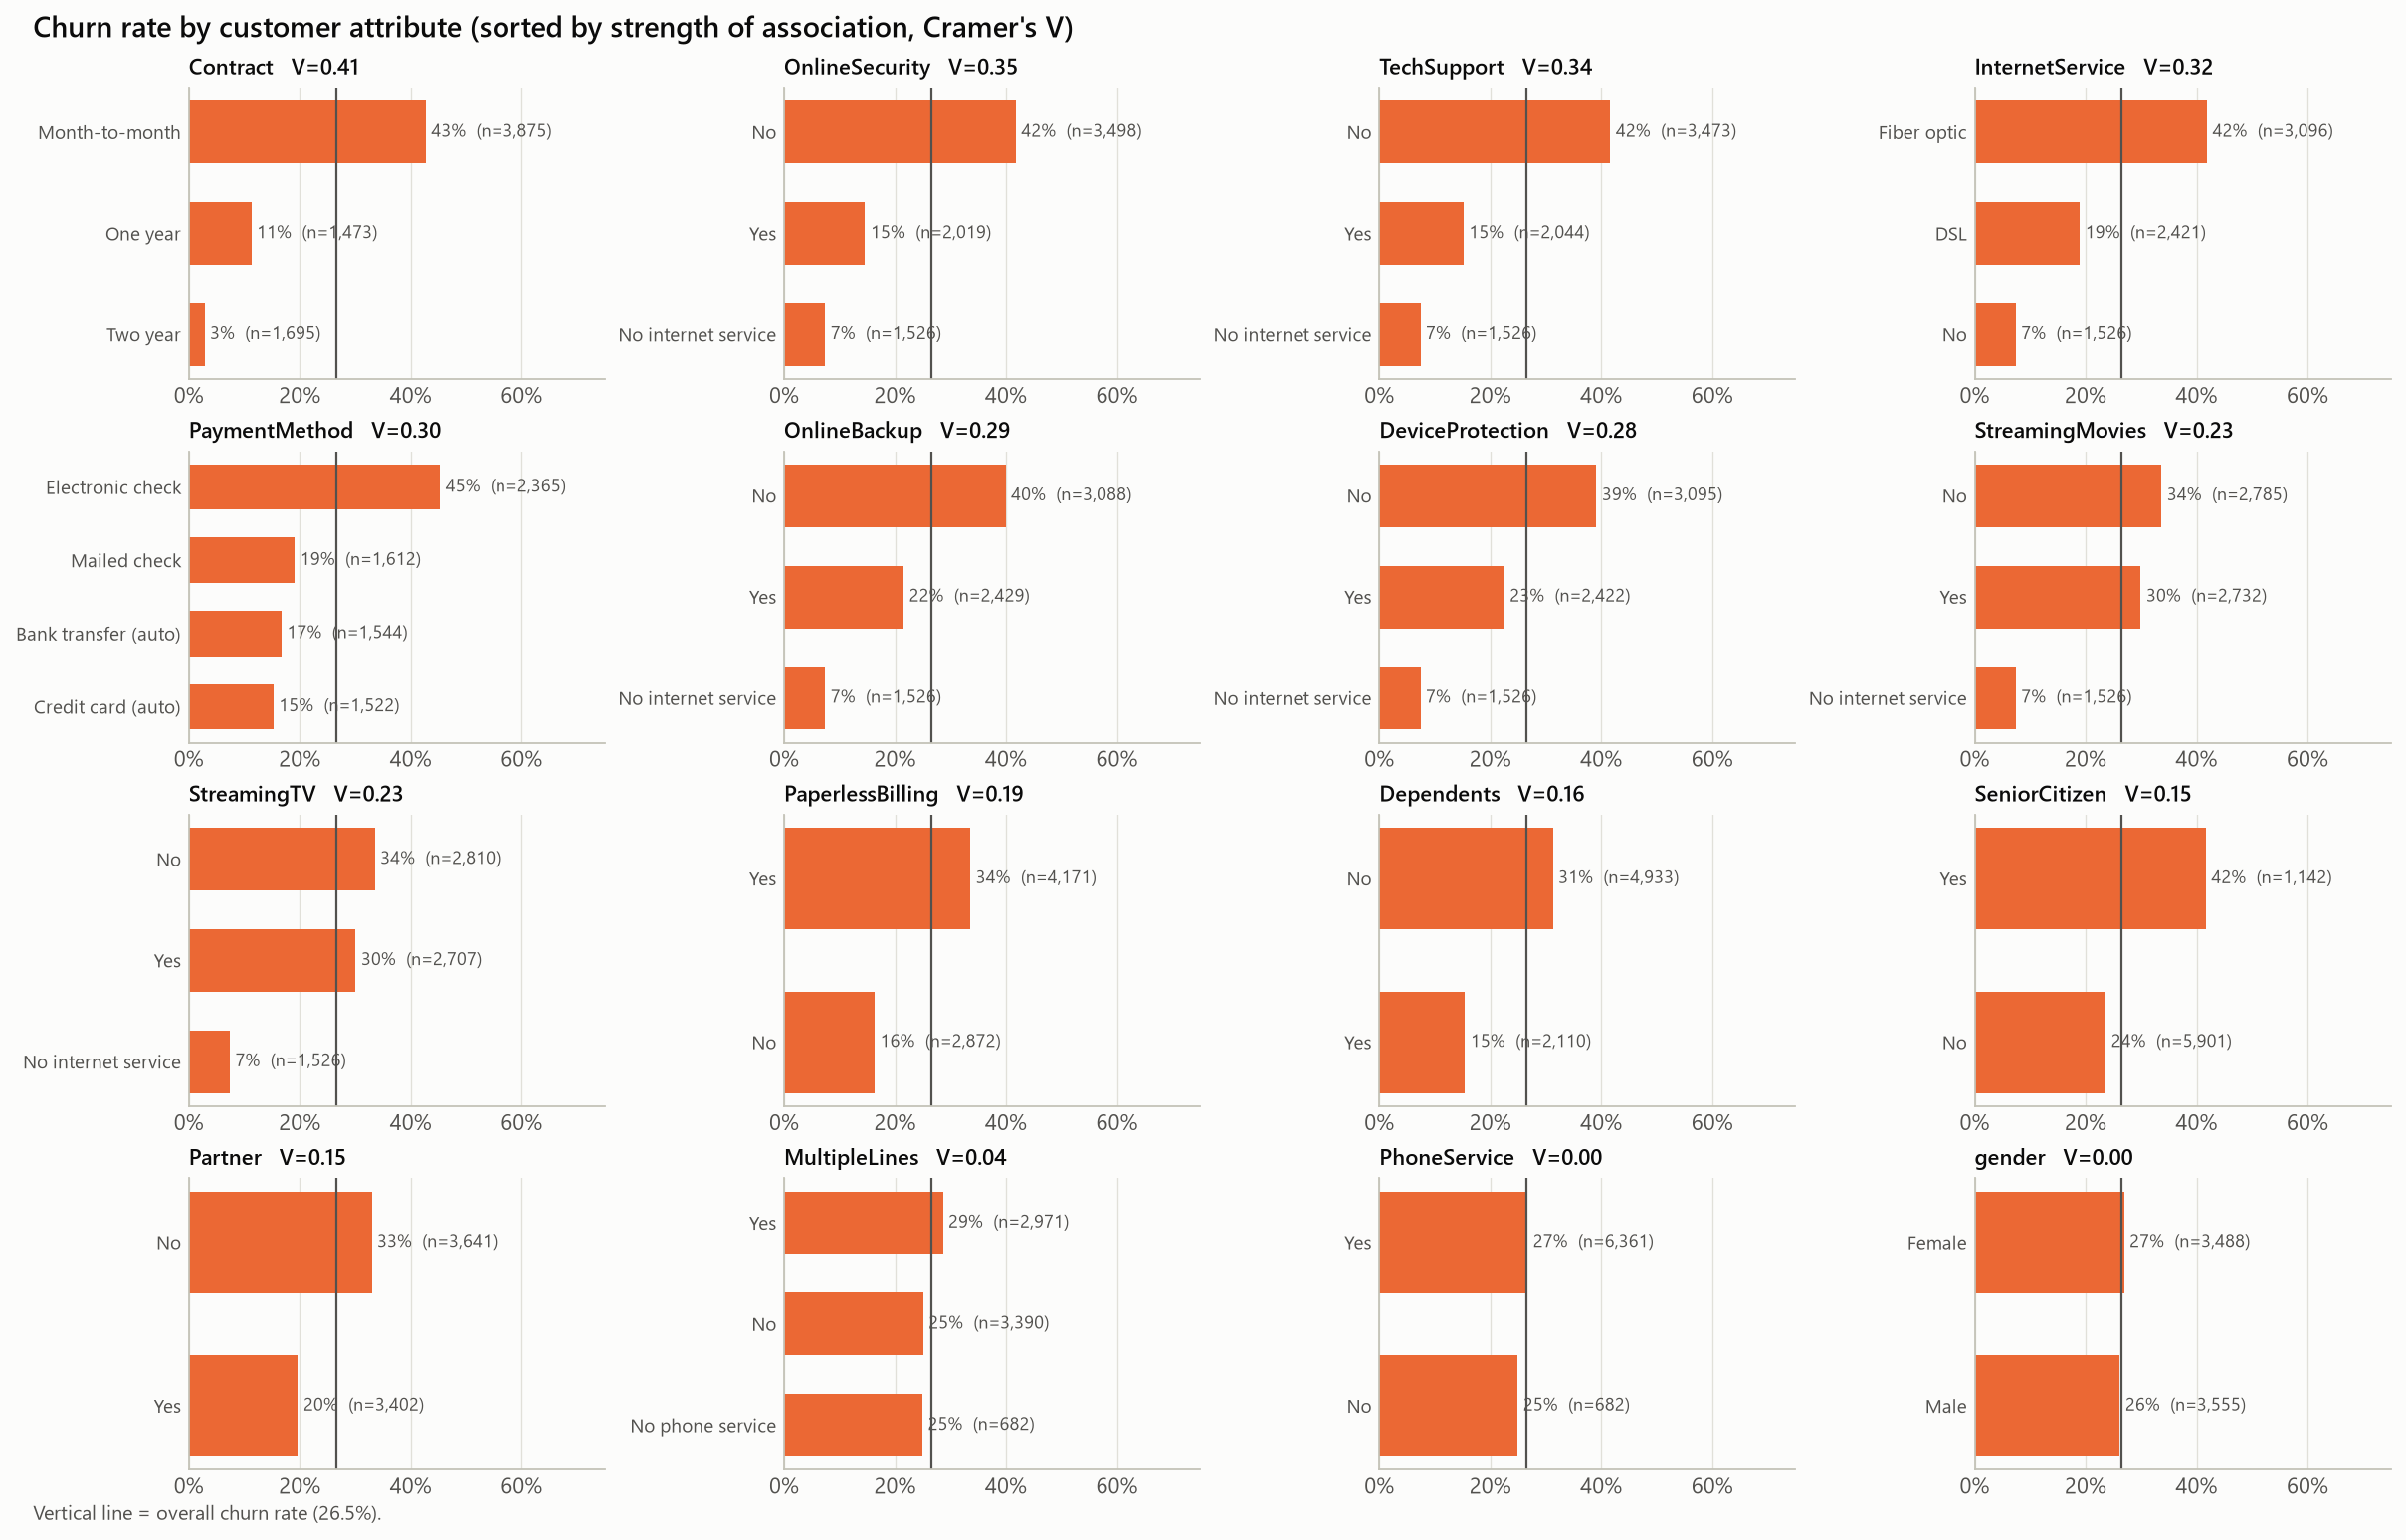

In [5]:
show("eda_churn_rate_by_category", 1200)

In [6]:
pd.read_csv(TAB / "stats_numeric_tests.csv")

,feature,median_churned,median_retained,mean_churned,mean_retained,mann_whitney_u,p_value,rank_biserial,point_biserial_r
0,tenure,10.00,38.000,17.9791,37.5700,2515538.0,2.4196e-208,-0.4797,-0.3522
1,MonthlyCharges,79.65,64.425,74.4413,61.2651,6003125.5,3.3116e-54,0.2416,0.1934
2,TotalCharges,703.55,1679.525,1531.7961,2549.9114,3381224.0,5.6850e-83,-0.3007,-0.1983


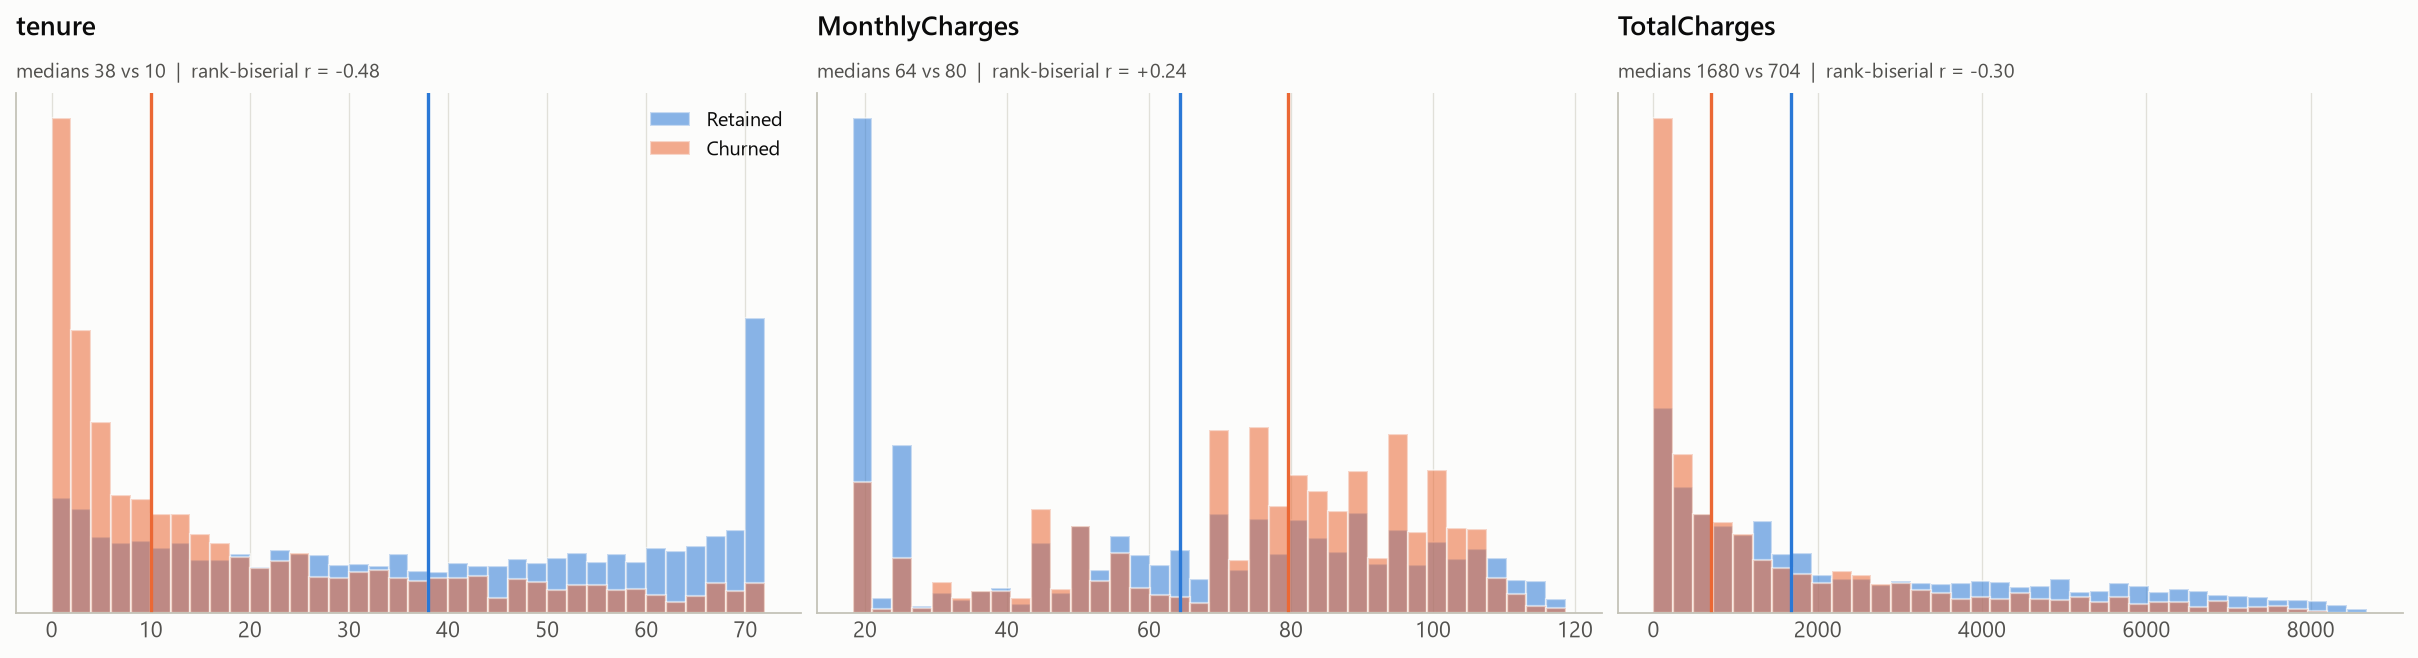

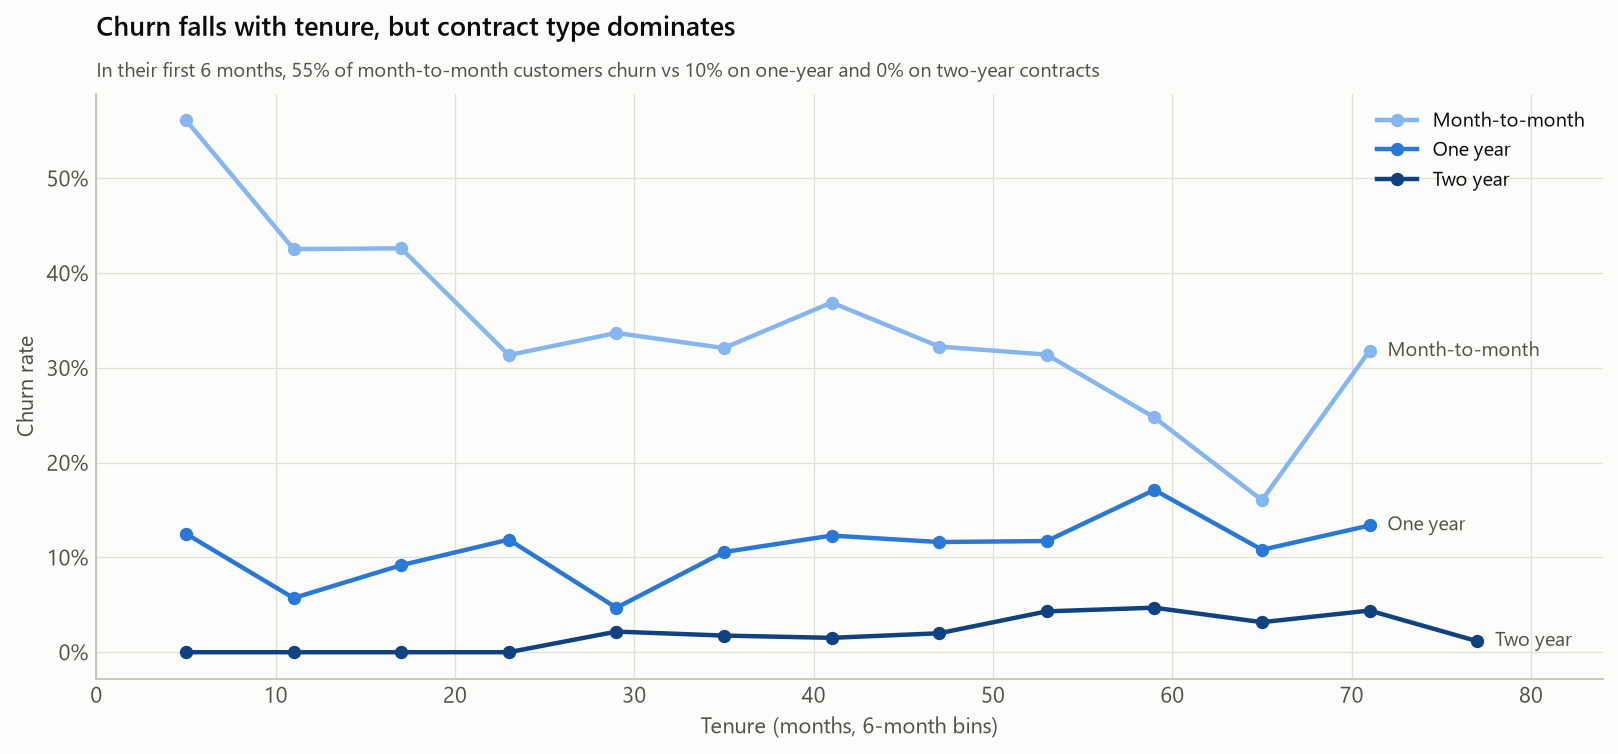

In [7]:
show("eda_numeric_distributions", 1200); show("eda_churn_by_tenure_and_contract")

Month-to-month customers churn **3.8x** more than one-year and **15x** more than two-year customers; churners took **$139,131** of monthly recurring revenue with them.

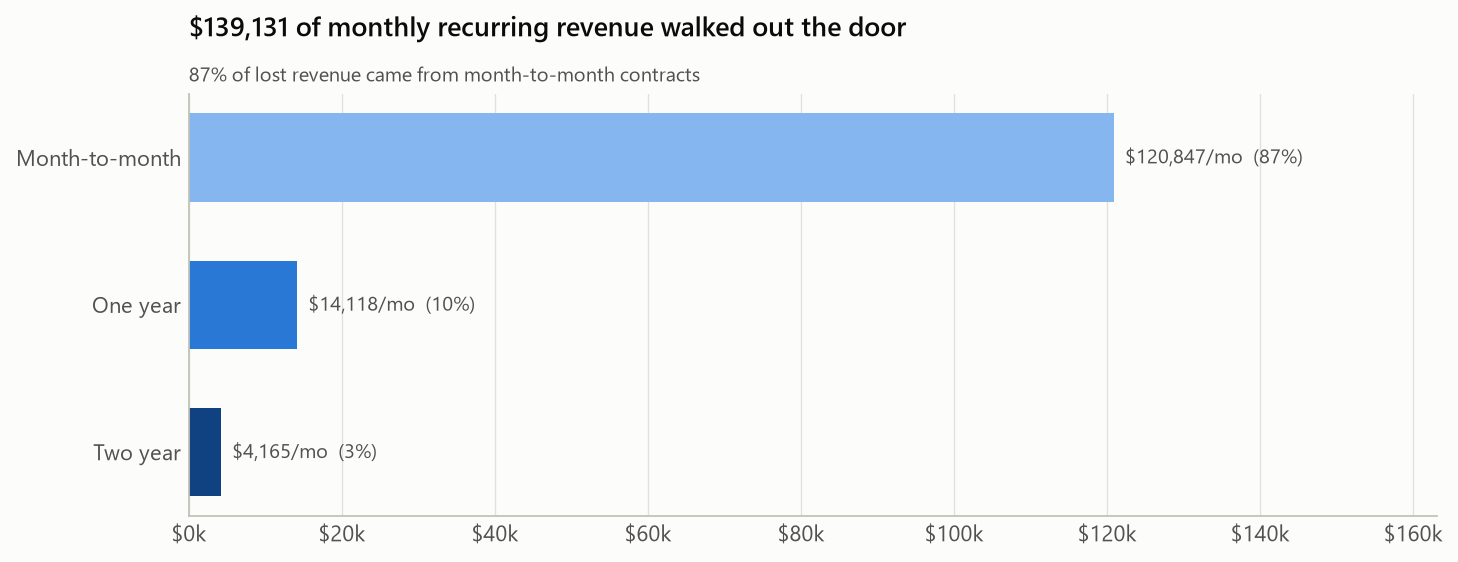

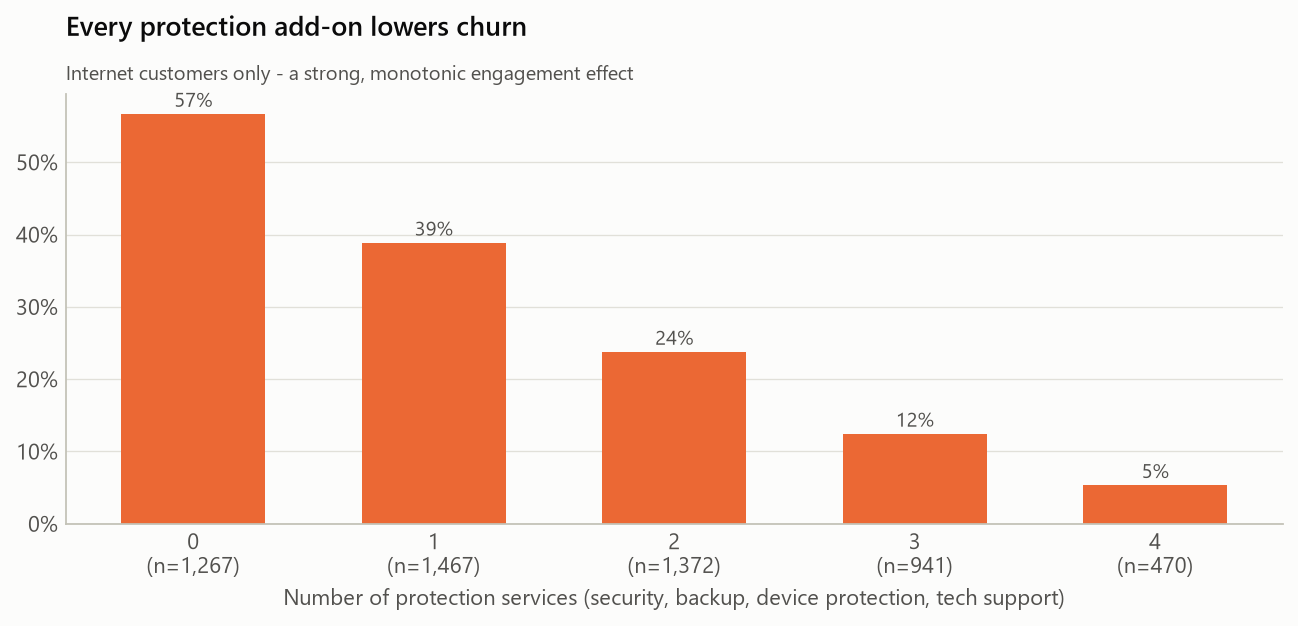

In [8]:
e = M["eda"]
display(Markdown(f"Month-to-month customers churn **{e['mtm_vs_one_year_ratio']:.1f}x** more than one-year and "
                 f"**{e['mtm_vs_two_year_ratio']:.0f}x** more than two-year customers; churners took "
                 f"**${e['monthly_revenue_lost']:,.0f}** of monthly recurring revenue with them."))
show("eda_revenue_at_risk", 850); show("eda_protection_services", 800)

Marginal churn rates confound factors (fibre customers also tend to be on month-to-month contracts). An
**inferential logistic regression** on a curated, non-collinear design isolates each factor's adjusted effect:

,term,odds_ratio,ci_low,ci_high,p_value
0,Internet: Fiber optic,2.1617,1.8349,2.5465,2.9658e-20
1,Paperless billing,1.4267,1.2304,1.6544,2.5392e-06
2,StreamingMovies,1.3953,1.1921,1.6332,3.3520e-05
3,StreamingTV,1.3712,1.1710,1.6056,8.8385e-05
4,Pay: Electronic check,1.3613,1.1692,1.5850,7.0904e-05
5,MultipleLines,1.3523,1.1608,1.5754,1.0726e-04
6,Senior citizen,1.2720,1.0773,1.5018,4.5310e-03
7,Partner,1.0379,0.8902,1.2100,6.3494e-01
8,DeviceProtection,1.0298,0.8821,1.2023,7.1023e-01
9,Pay: Mailed check,0.9139,0.7471,1.1180,3.8123e-01


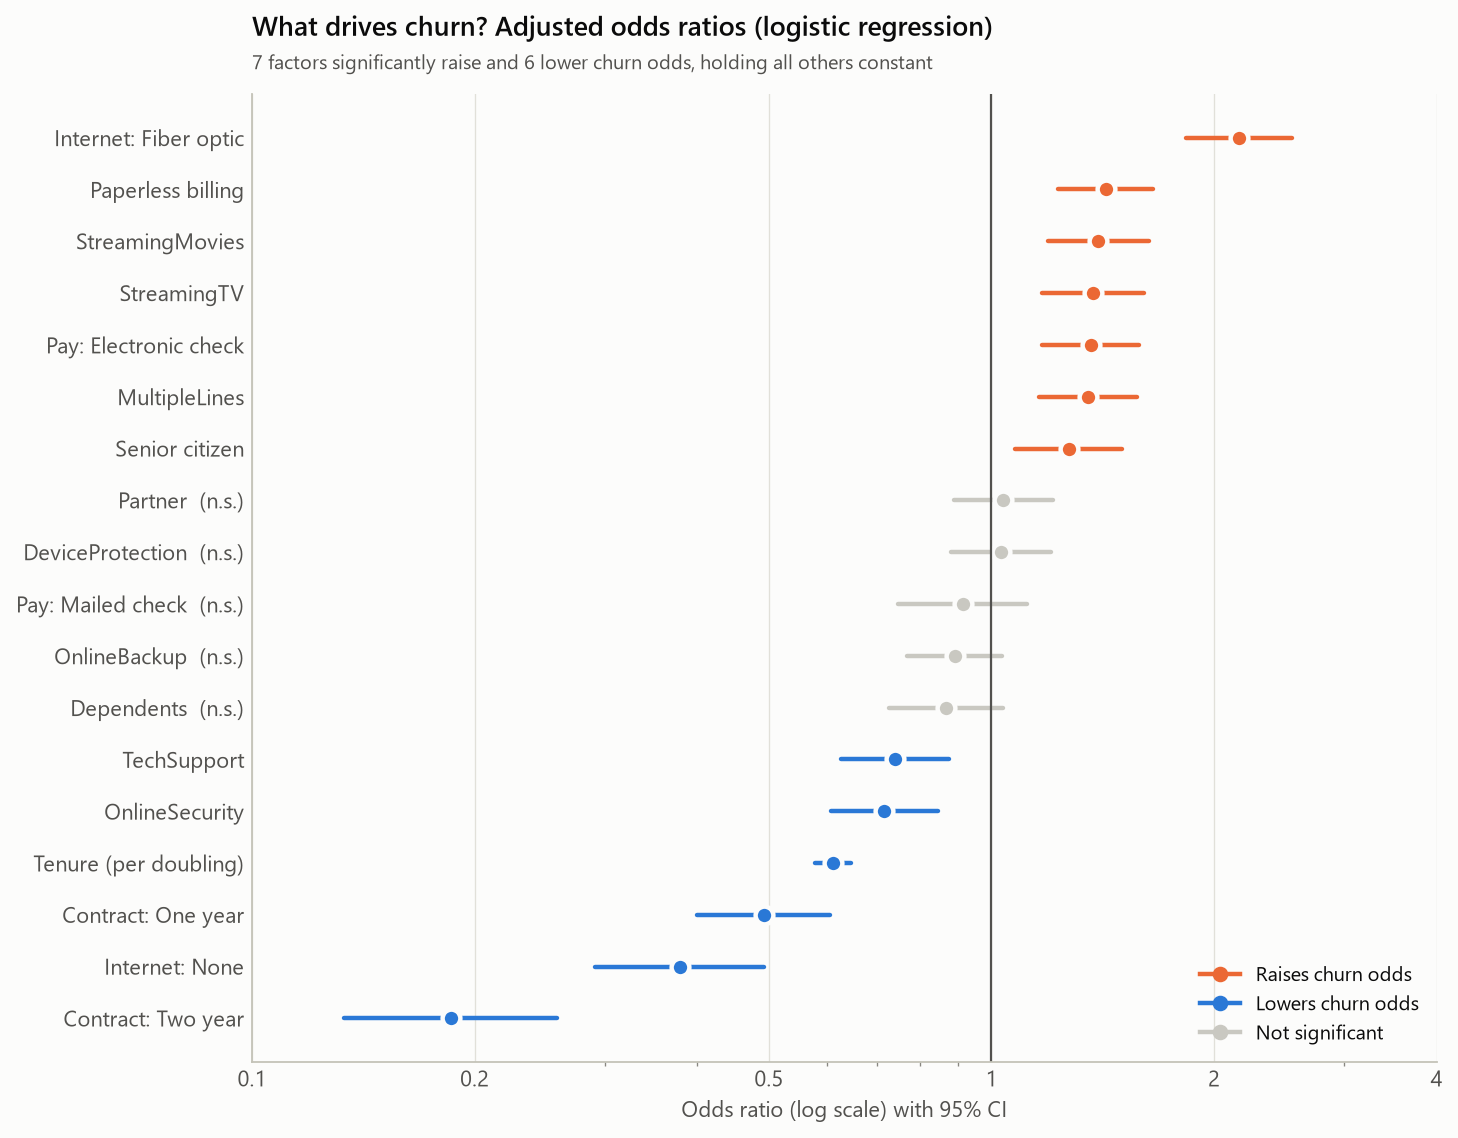

In [9]:
display(pd.read_csv(TAB / "stats_logit_odds_ratios.csv")); show("eda_odds_ratios", 850)

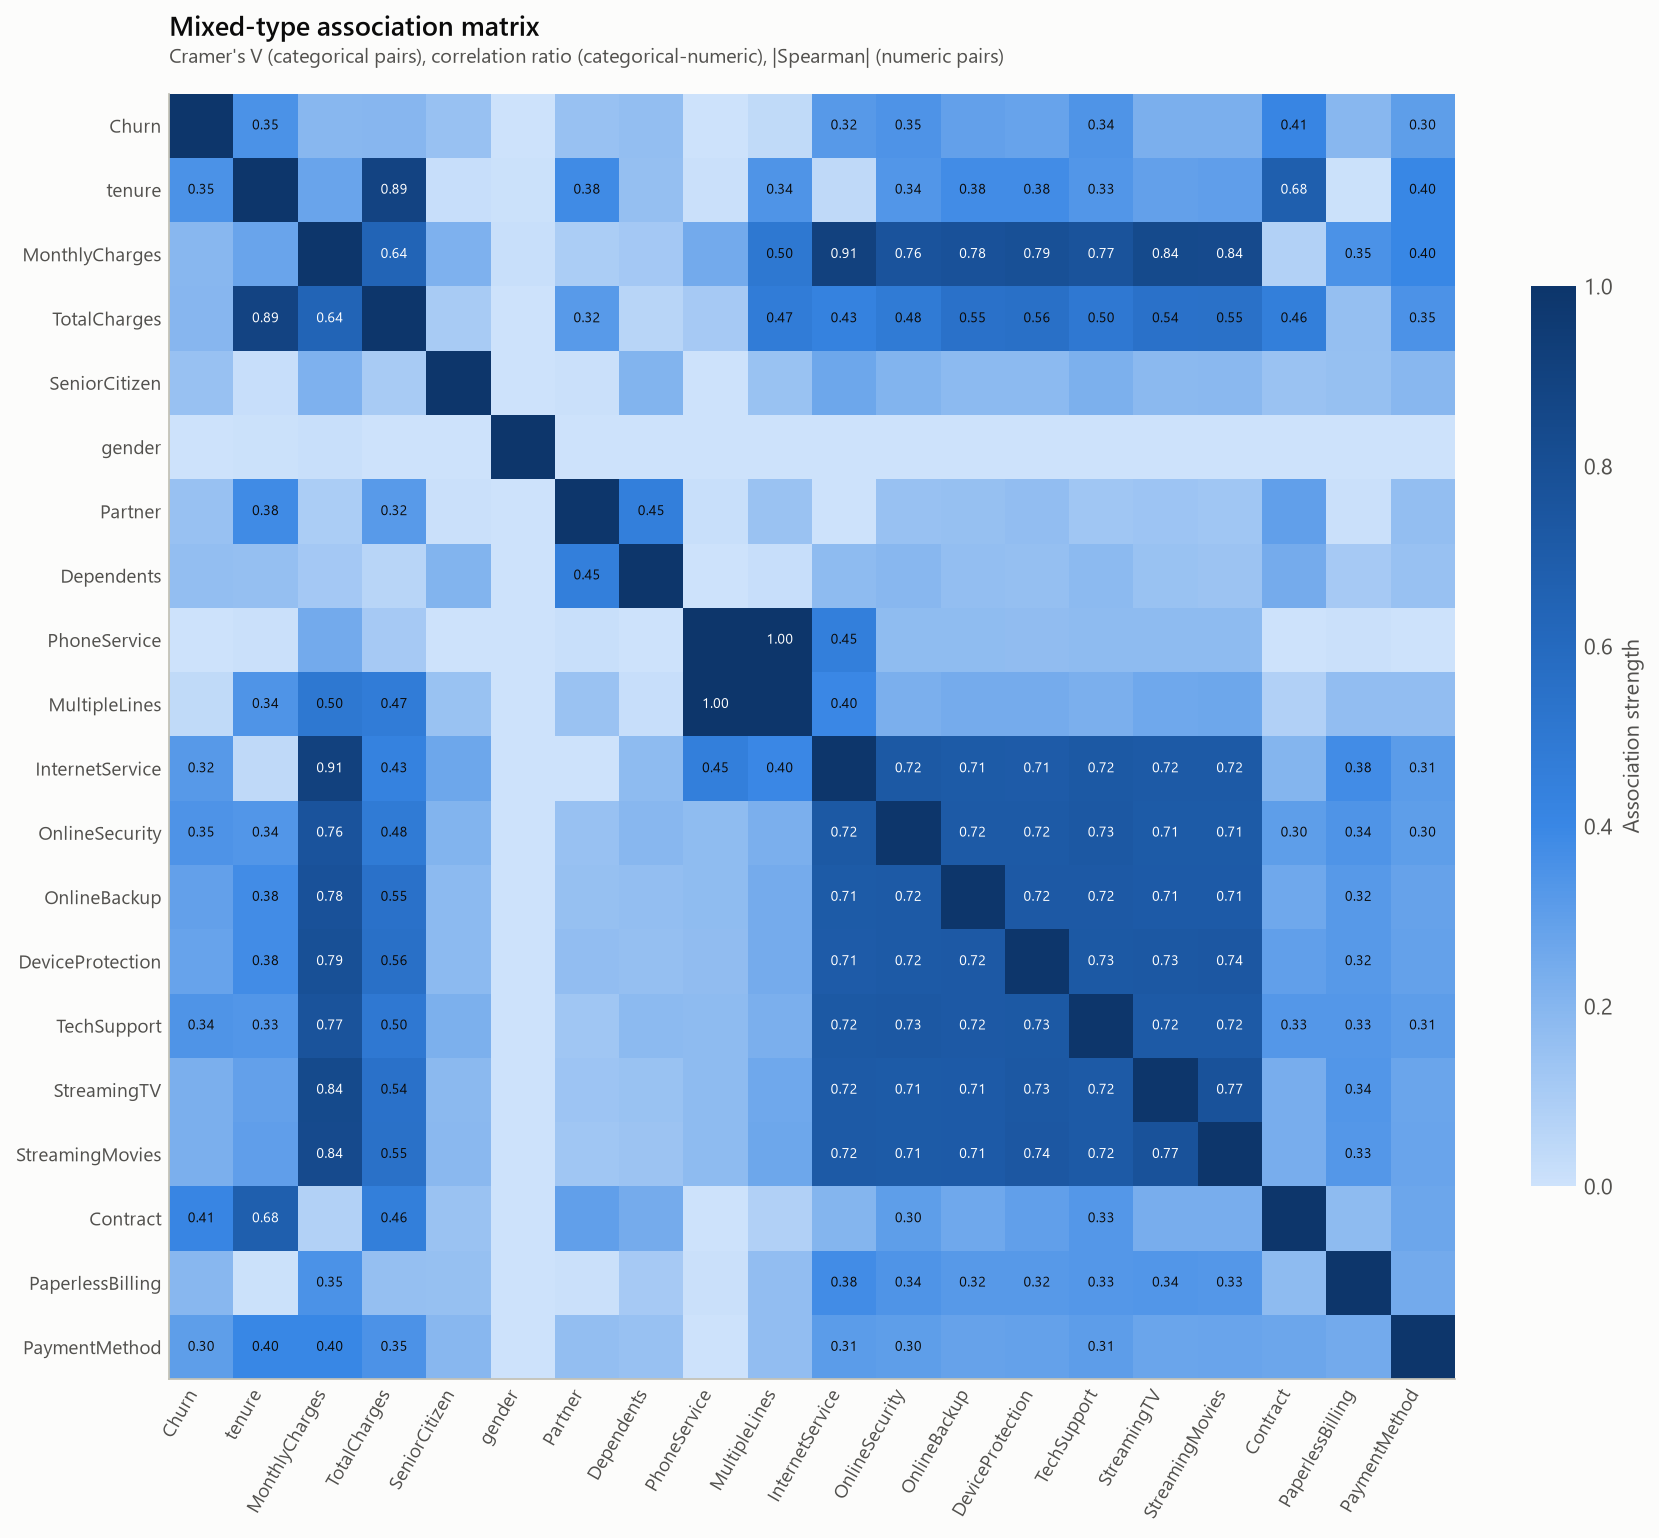

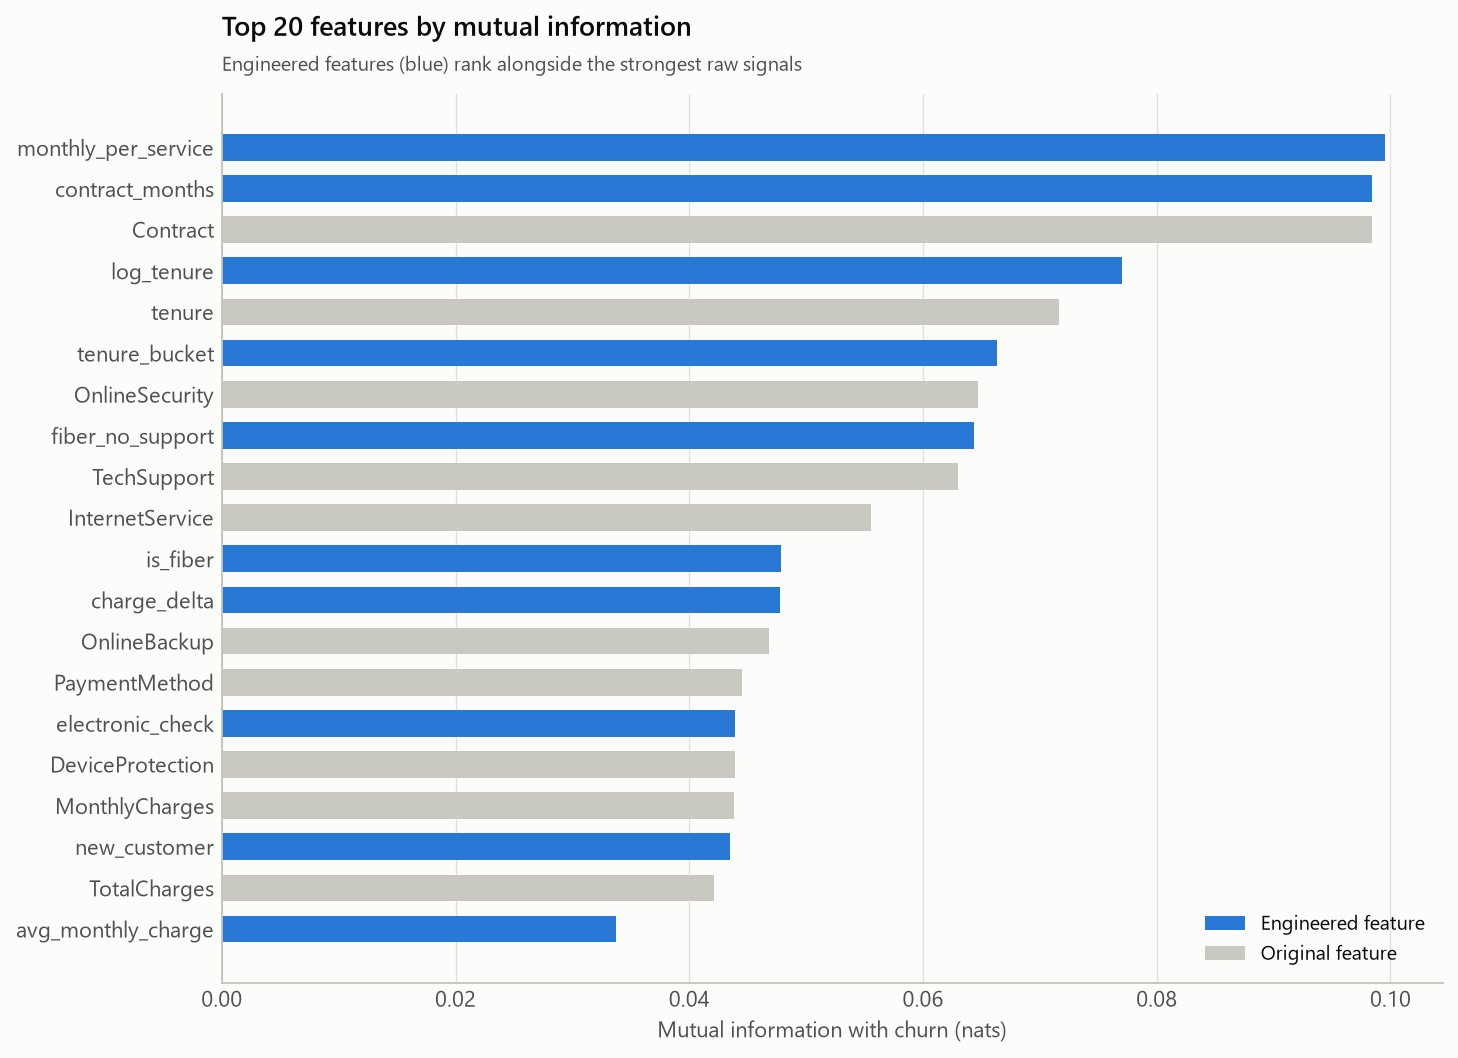

In [10]:
show("eda_association_matrix", 850); show("eda_mutual_information", 800)

## 3. Survival analysis

Treating `tenure` as time-to-event (active customers are right-censored) answers *when* customers leave.

12-month retention: 0.843 | Cox concordance: 0.861
Median lifetime by contract (months; None = never reaches 50%): {'Month-to-month': 35.0, 'One year': None, 'Two year': None}
PH-assumption violations (p<0.01): ['Contract: One year', 'OnlineSecurity', 'Pay: Automatic', 'TechSupport', 'StreamingTV']


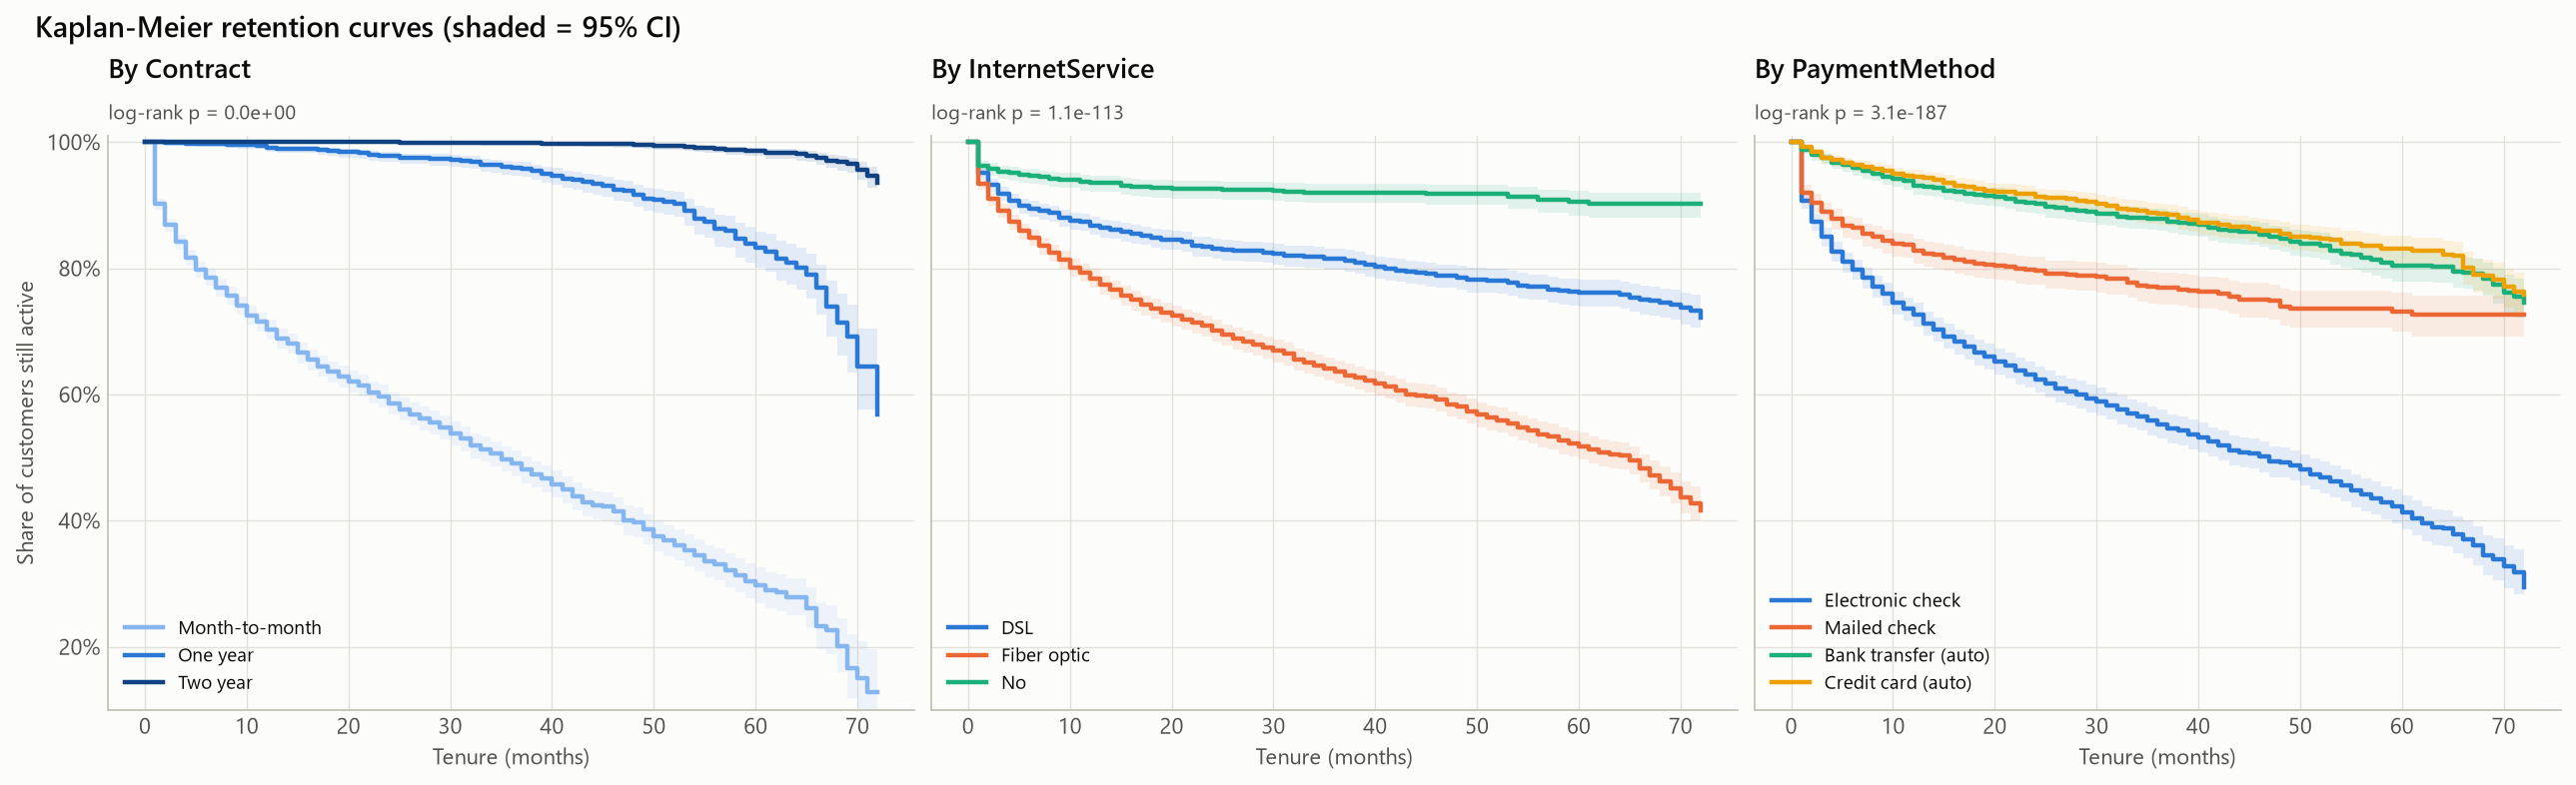

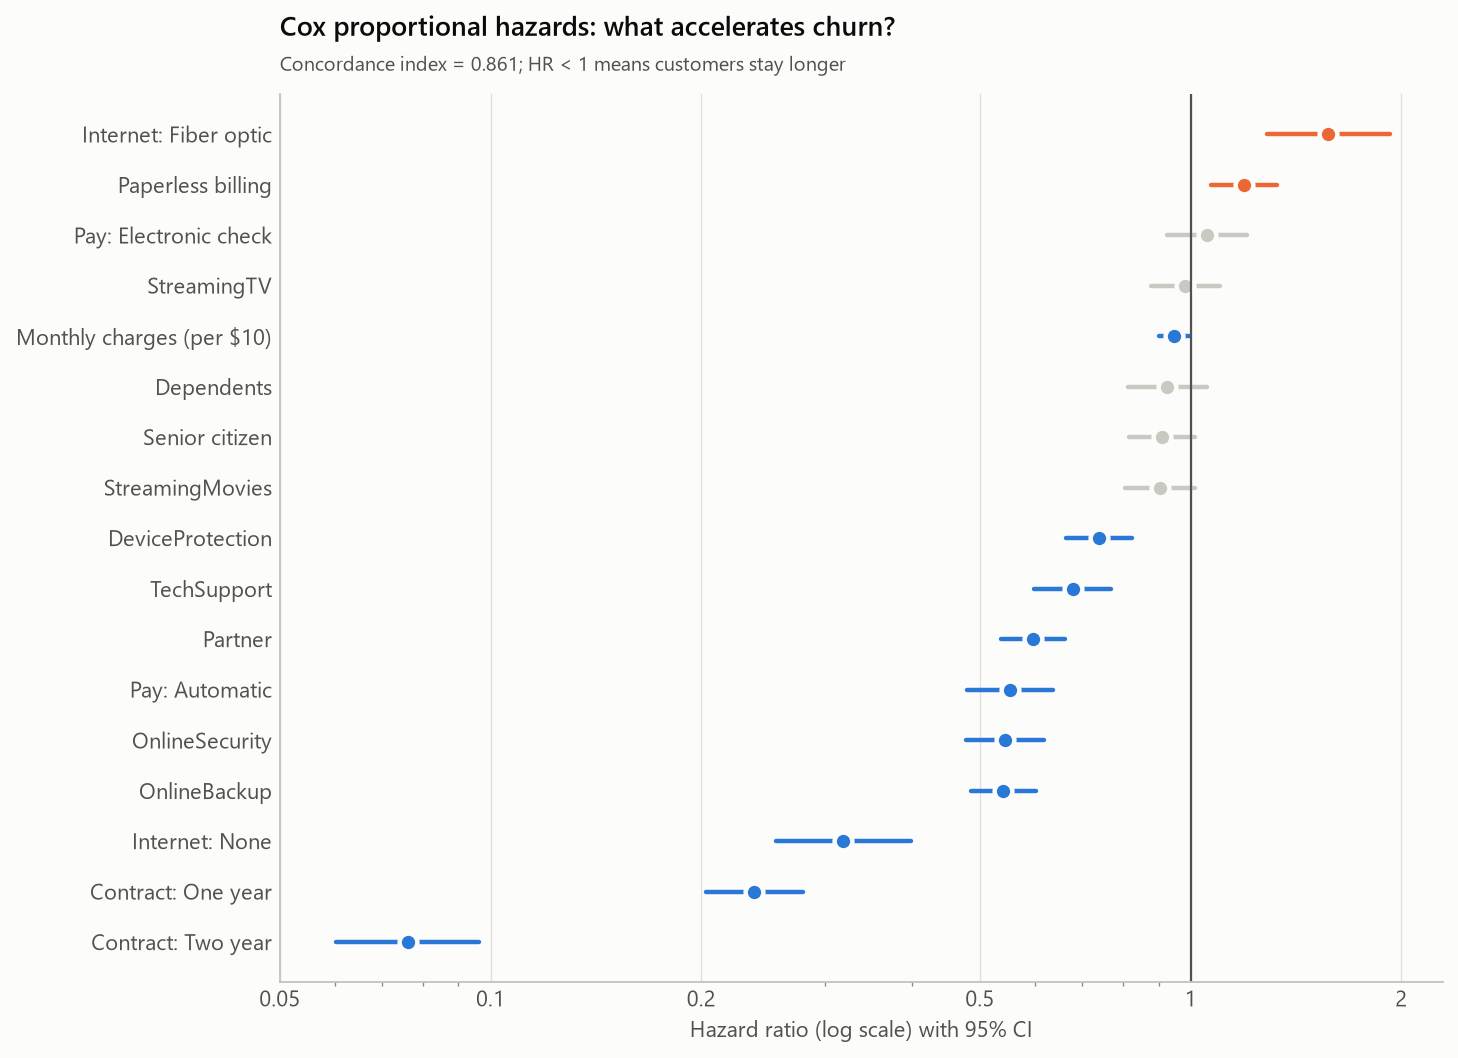

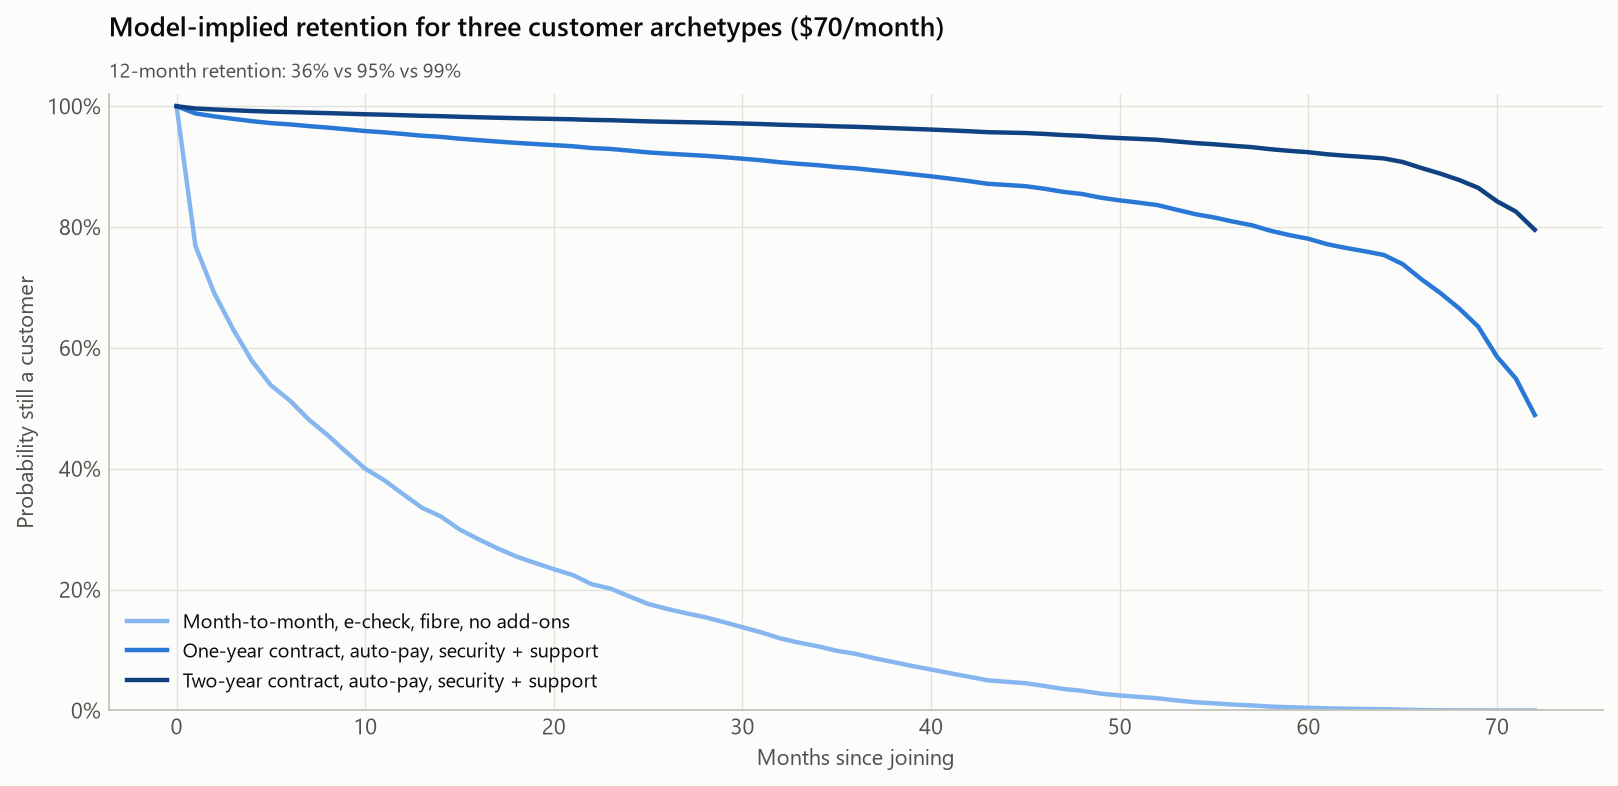

In [11]:
s = M["survival"]
print("12-month retention:", round(s["retention_12m_overall"], 3), "| Cox concordance:", round(s["cox_concordance"], 3))
print("Median lifetime by contract (months; None = never reaches 50%):", s["median_lifetime_by_contract"])
print("PH-assumption violations (p<0.01):", s["ph_violations"])
show("survival_kaplan_meier", 1200); show("survival_cox_hazard_ratios", 800); show("survival_archetypes", 850)

## 4. Modelling

* **Features:** stateless, leak-free domain features (service counts, price change vs. historical average, price per
  service, commitment, auto-pay, fibre-without-support flag, tenure buckets).
* **Models:** logistic regression, random forest, XGBoost, LightGBM, CatBoost and **TabularNet** - a PyTorch MLP
  with entity embeddings for categoricals - each tuned with Optuna (TPE + median pruning) on identical 5-fold
  stratified CV splits; plus a stacked (logistic meta-learner on out-of-fold log-odds) and a soft-voting ensemble.
* **Selection on cross-validation only** - best CV AUC, ties within one standard error broken by calibration; the
  20% hold-out set is scored once at the end.

In [12]:
cv = pd.DataFrame(M["modelling"]["cv"])[["model", "cv_auc_mean", "cv_auc_std", "oof_pr_auc", "oof_brier"]]
test = pd.DataFrame(M["modelling"]["test"])[["model", "roc_auc", "auc_ci_low", "auc_ci_high", "pr_auc", "brier"]]
cv.merge(test, on="model").sort_values("cv_auc_mean", ascending=False)

,model,cv_auc_mean,cv_auc_std,oof_pr_auc,oof_brier,roc_auc,auc_ci_low,auc_ci_high,pr_auc,brier
7,Soft-Voting Ensemble,0.8512,0.0116,0.6689,0.1360,0.8487,0.8258,0.8700,0.6674,0.1378
6,Stacked Ensemble,0.8511,0.0111,0.6682,0.1329,0.8492,0.8262,0.8705,0.6663,0.1342
2,XGBoost,0.8507,0.0118,0.6660,0.1332,0.8472,0.8237,0.8689,0.6652,0.1350
0,Logistic Regression,0.8507,0.0113,0.6691,0.1615,0.8487,0.8264,0.8700,0.6641,0.1638
4,CatBoost,0.8503,0.0116,0.6674,0.1333,0.8480,0.8245,0.8694,0.6667,0.1346
3,LightGBM,0.8500,0.0117,0.6651,0.1336,0.8472,0.8239,0.8690,0.6637,0.1349
1,Random Forest,0.8478,0.0097,0.6613,0.1343,0.8468,0.8243,0.8684,0.6613,0.1349
5,TabularNet (DL),0.8473,0.0110,0.6578,0.1352,0.8474,0.8253,0.8691,0.6606,0.1363


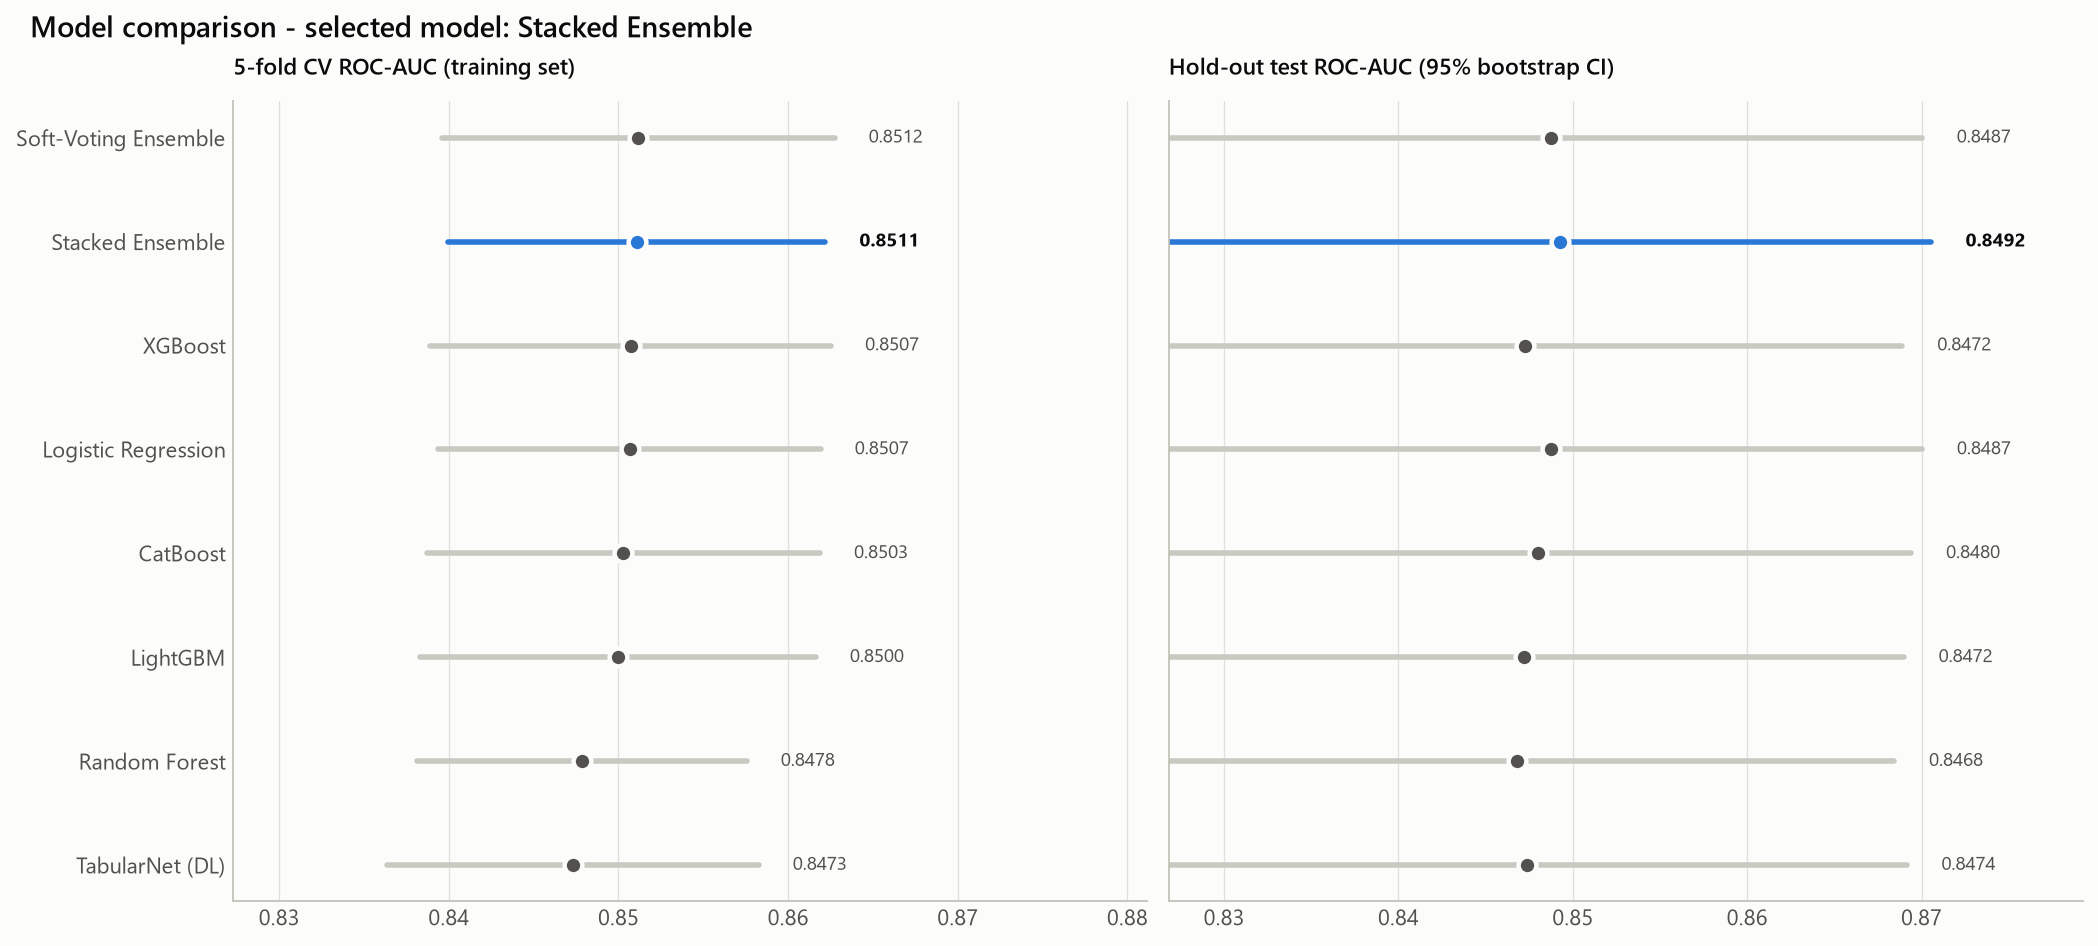

In [13]:
show("model_comparison", 1150)

Are the differences real? DeLong's test for correlated ROC curves (deployed model vs. each alternative):

In [14]:
pd.DataFrame(M["modelling"]["delong"])

,model,auc_stacked_ensemble,auc_other,diff,z,p_value
0,Logistic Regression,0.8492,0.8487,0.0005,0.4750,0.6348
1,Random Forest,0.8492,0.8468,0.0024,1.0757,0.2820
2,XGBoost,0.8492,0.8472,0.0020,1.8922,0.0585
3,LightGBM,0.8492,0.8472,0.0020,1.4530,0.1462
4,CatBoost,0.8492,0.8480,0.0013,0.9603,0.3369
5,TabularNet (DL),0.8492,0.8474,0.0019,0.7572,0.4489
6,Soft-Voting Ensemble,0.8492,0.8487,0.0005,0.7755,0.4380


On this dataset the signal is largely additive, so the models cluster tightly and a well-built logistic regression
is a very strong baseline. What separates them in practice is **calibration** (Brier score) - and calibrated
probabilities are exactly what the value-aware targeting rule in section 6 needs.

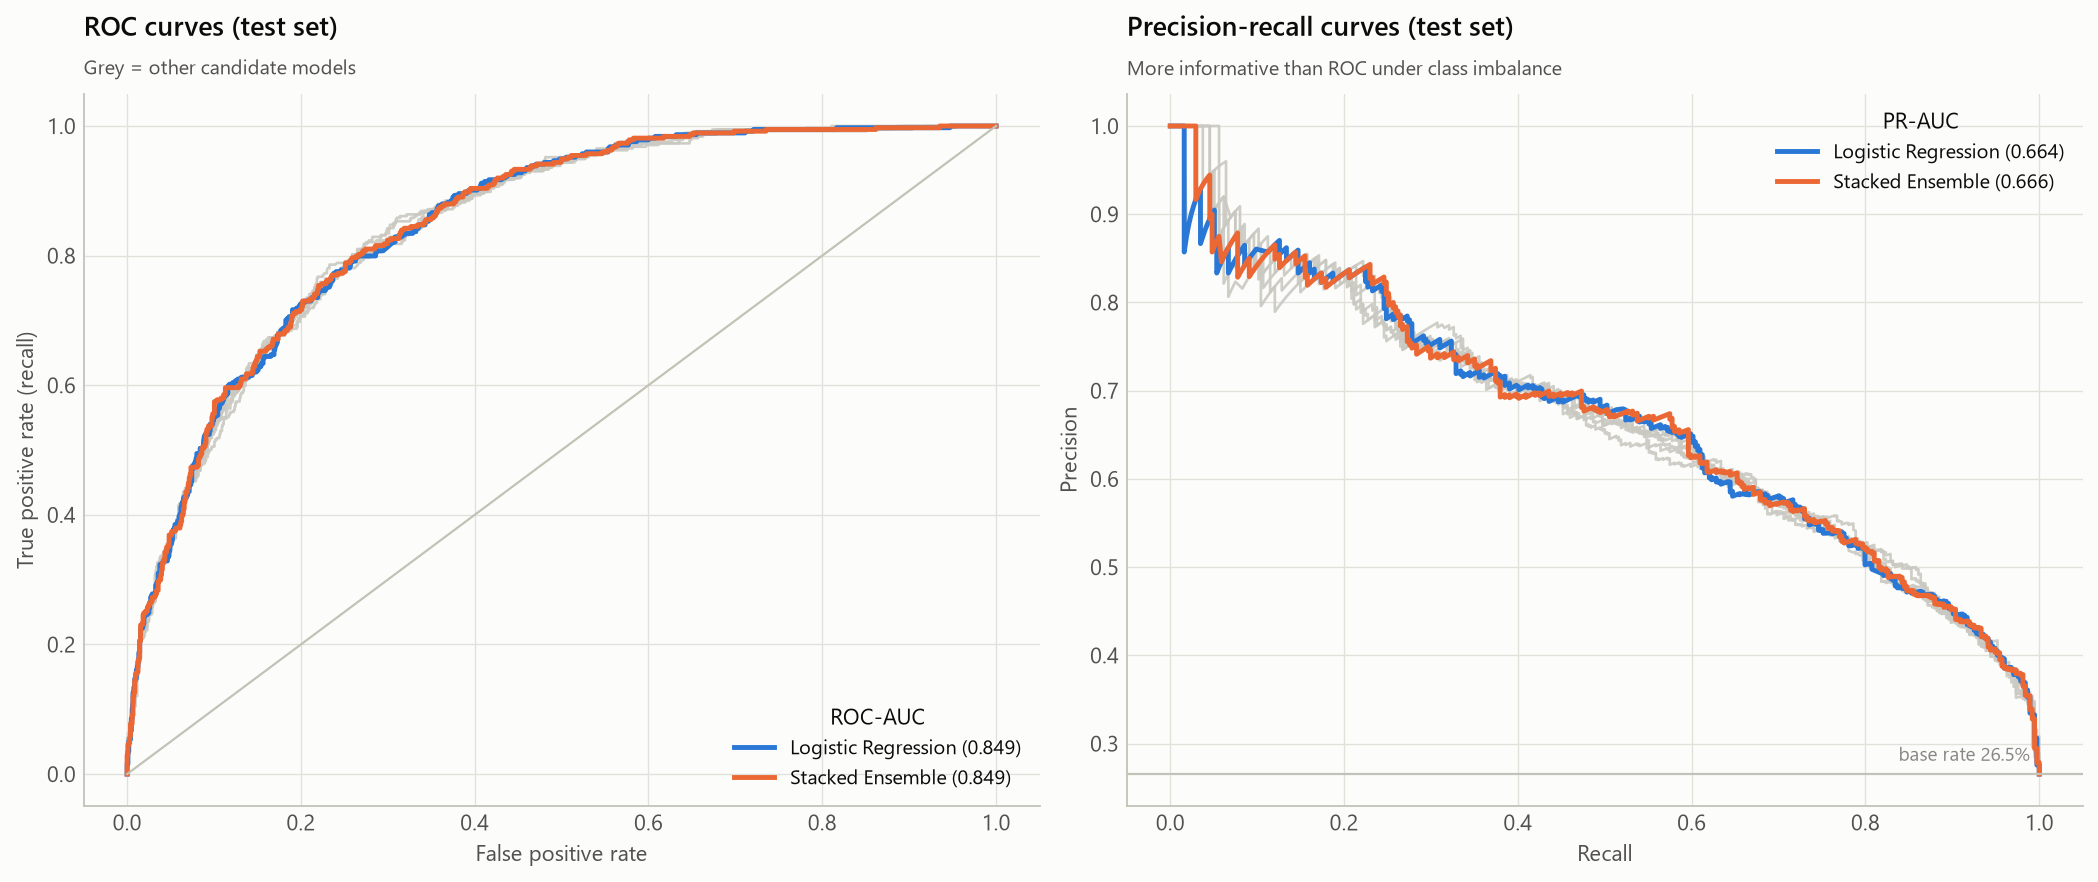

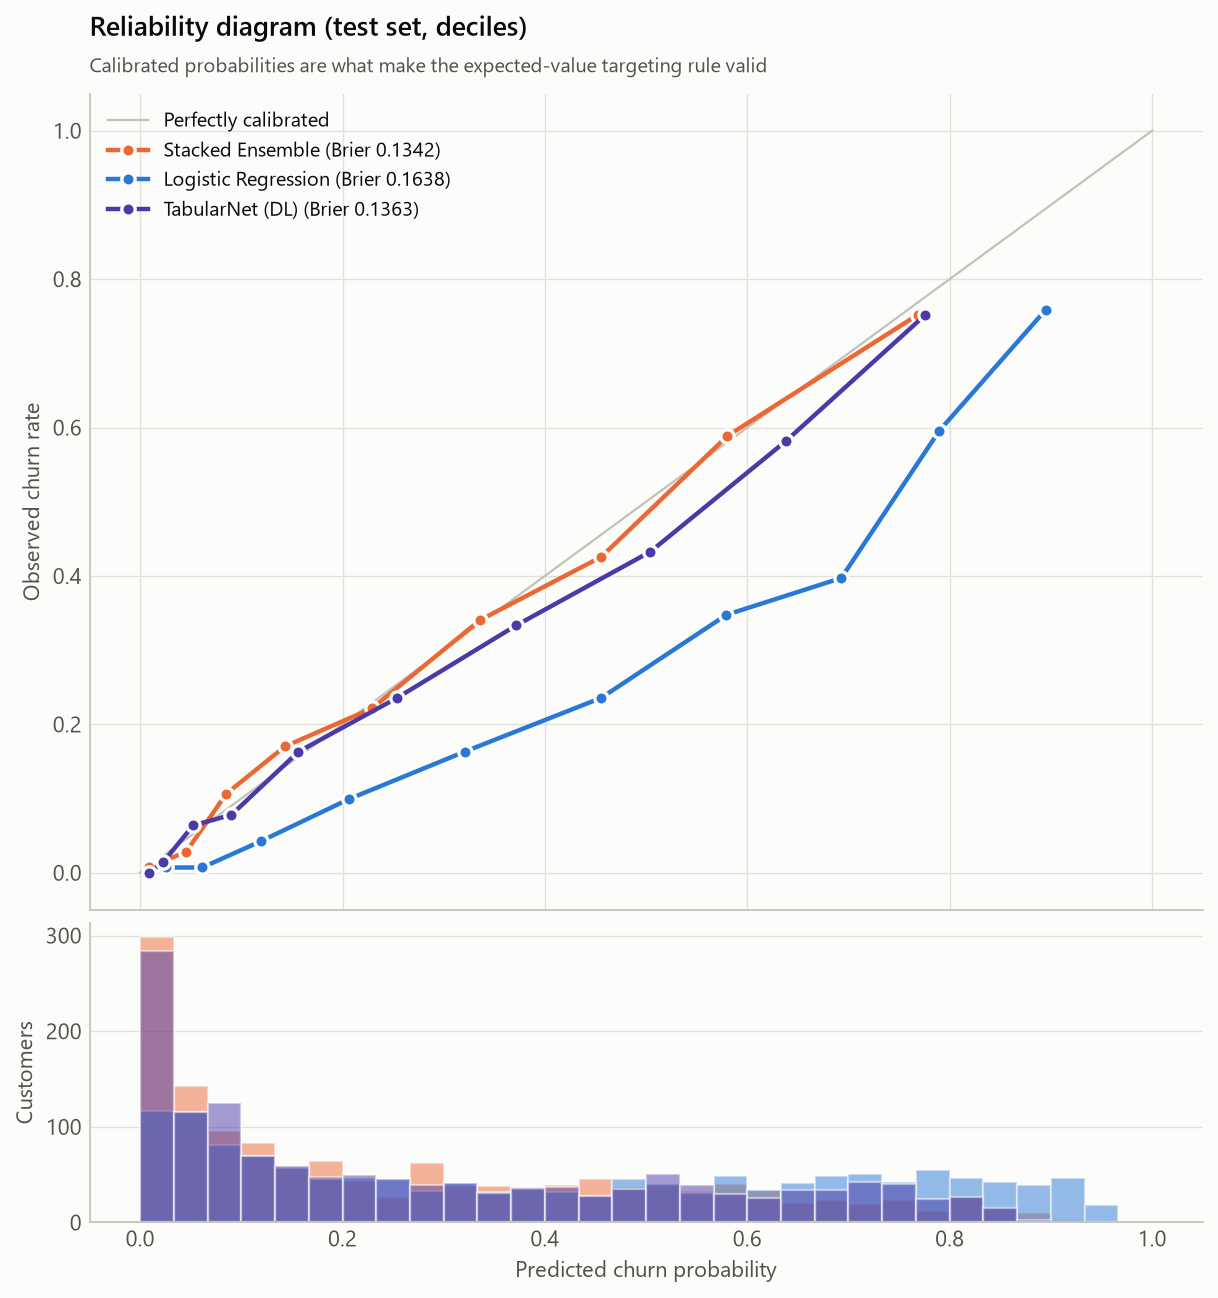

In [15]:
show("roc_pr_curves", 1150); show("calibration", 650)

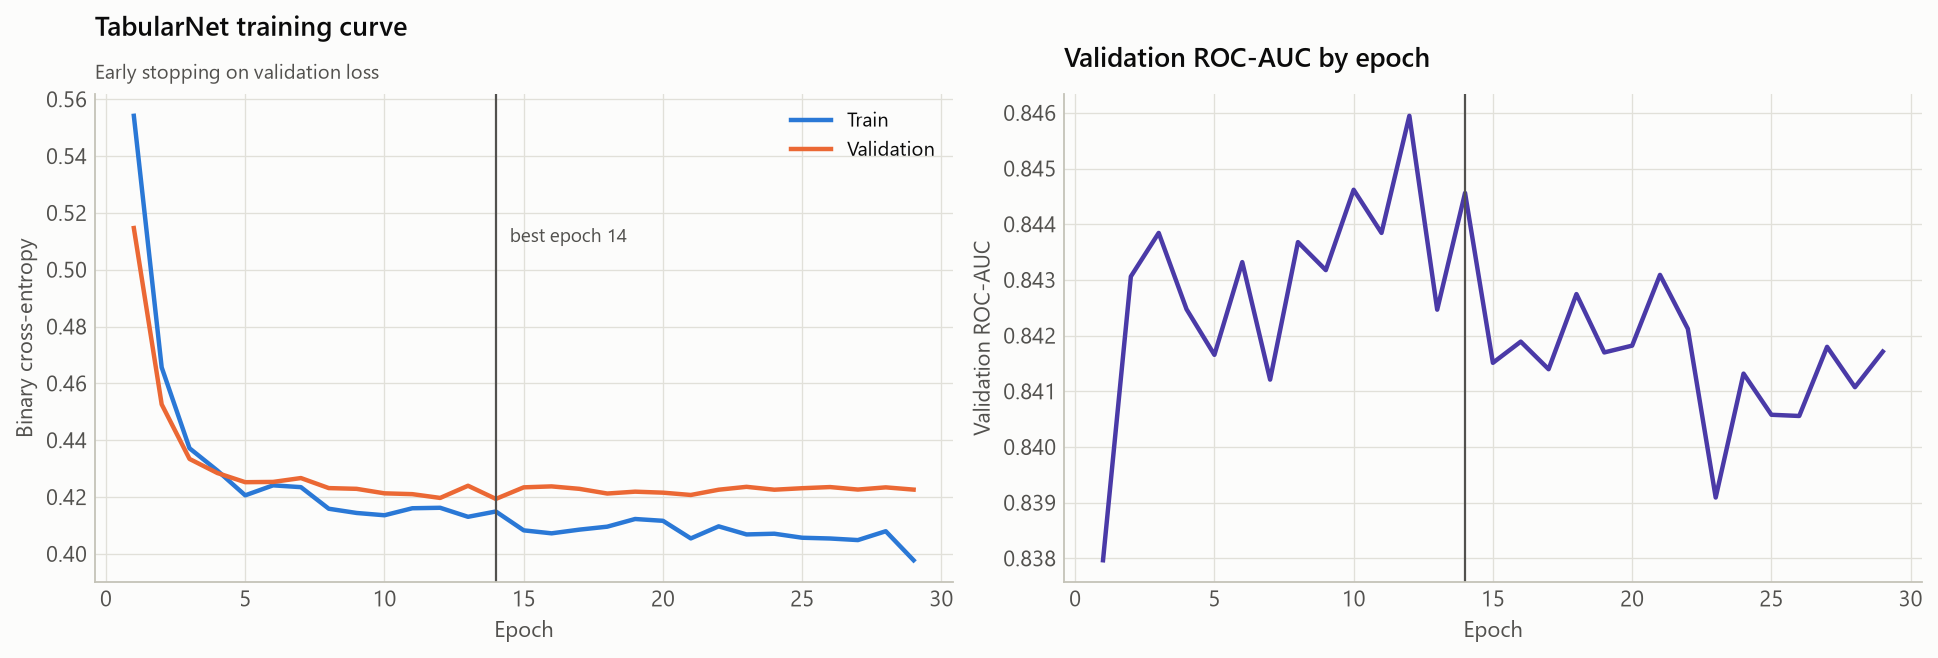

In [16]:
show("dl_learning_curve", 1000)

**Class imbalance:** does re-weighting or SMOTE help?

In [17]:
pd.DataFrame(M["modelling"]["imbalance"])

,strategy,roc_auc,pr_auc,brier,mean_predicted_prob,recall_at_0.5,precision_at_0.5
0,None (natural 26.5% churn),0.8492,0.6651,0.1336,0.2651,0.5224,0.6641
1,Class weighting (scale_pos_weight),0.8489,0.6634,0.1616,0.4101,0.8114,0.5160
2,SMOTE oversampling,0.8452,0.6558,0.1394,0.3168,0.6488,0.5951
3,Random undersampling,0.8489,0.6597,0.1632,0.4152,0.8120,0.5131


Re-balancing doesn't improve ranking (AUC) but inflates probabilities and worsens the Brier score. Imbalance is a
*decision-threshold* problem, so the natural distribution is kept and the threshold comes from the economics.

## 5. Hold-out evaluation of the deployed model

In [18]:
md_ = M["metadata"]
print(md_["model_name"], "| profit-optimal threshold:", round(md_["threshold"], 3), "| F1-optimal:", round(md_["f1_threshold"], 3))
pd.Series(md_["test_metrics"]).round(4)

Stacked Ensemble | profit-optimal threshold: 0.2 | F1-optimal: 0.357


roc_auc        0.8492
auc_ci_low     0.8262
auc_ci_high    0.8705
pr_auc         0.6663
brier          0.1342
log_loss       0.4107
precision      0.4760
recall         0.8476
f1             0.6096
specificity    0.6628
mcc            0.4514
lift_top10     2.8322
dtype: float64

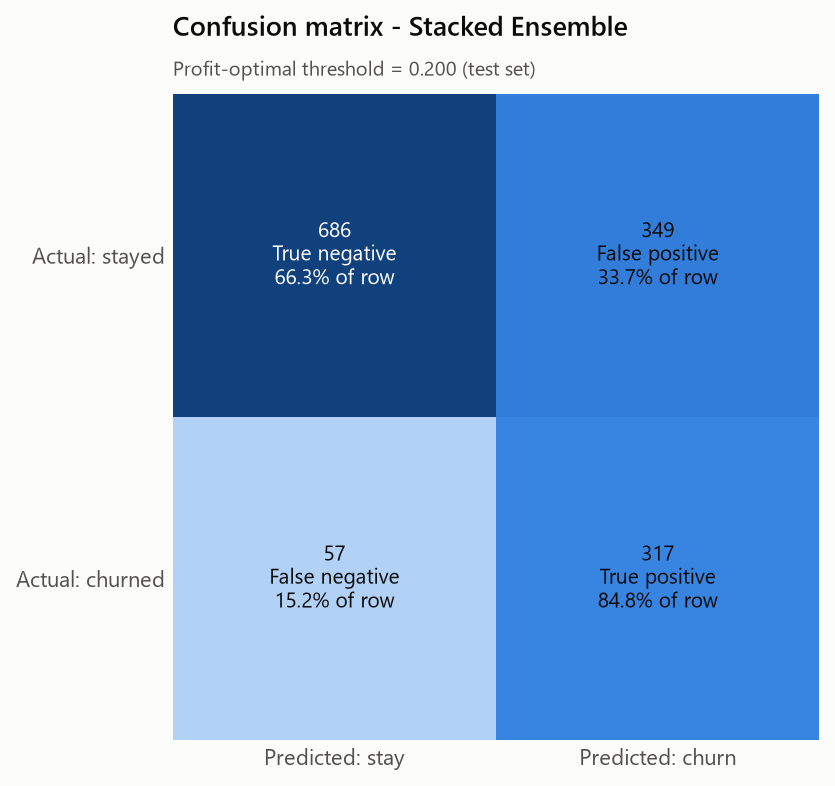

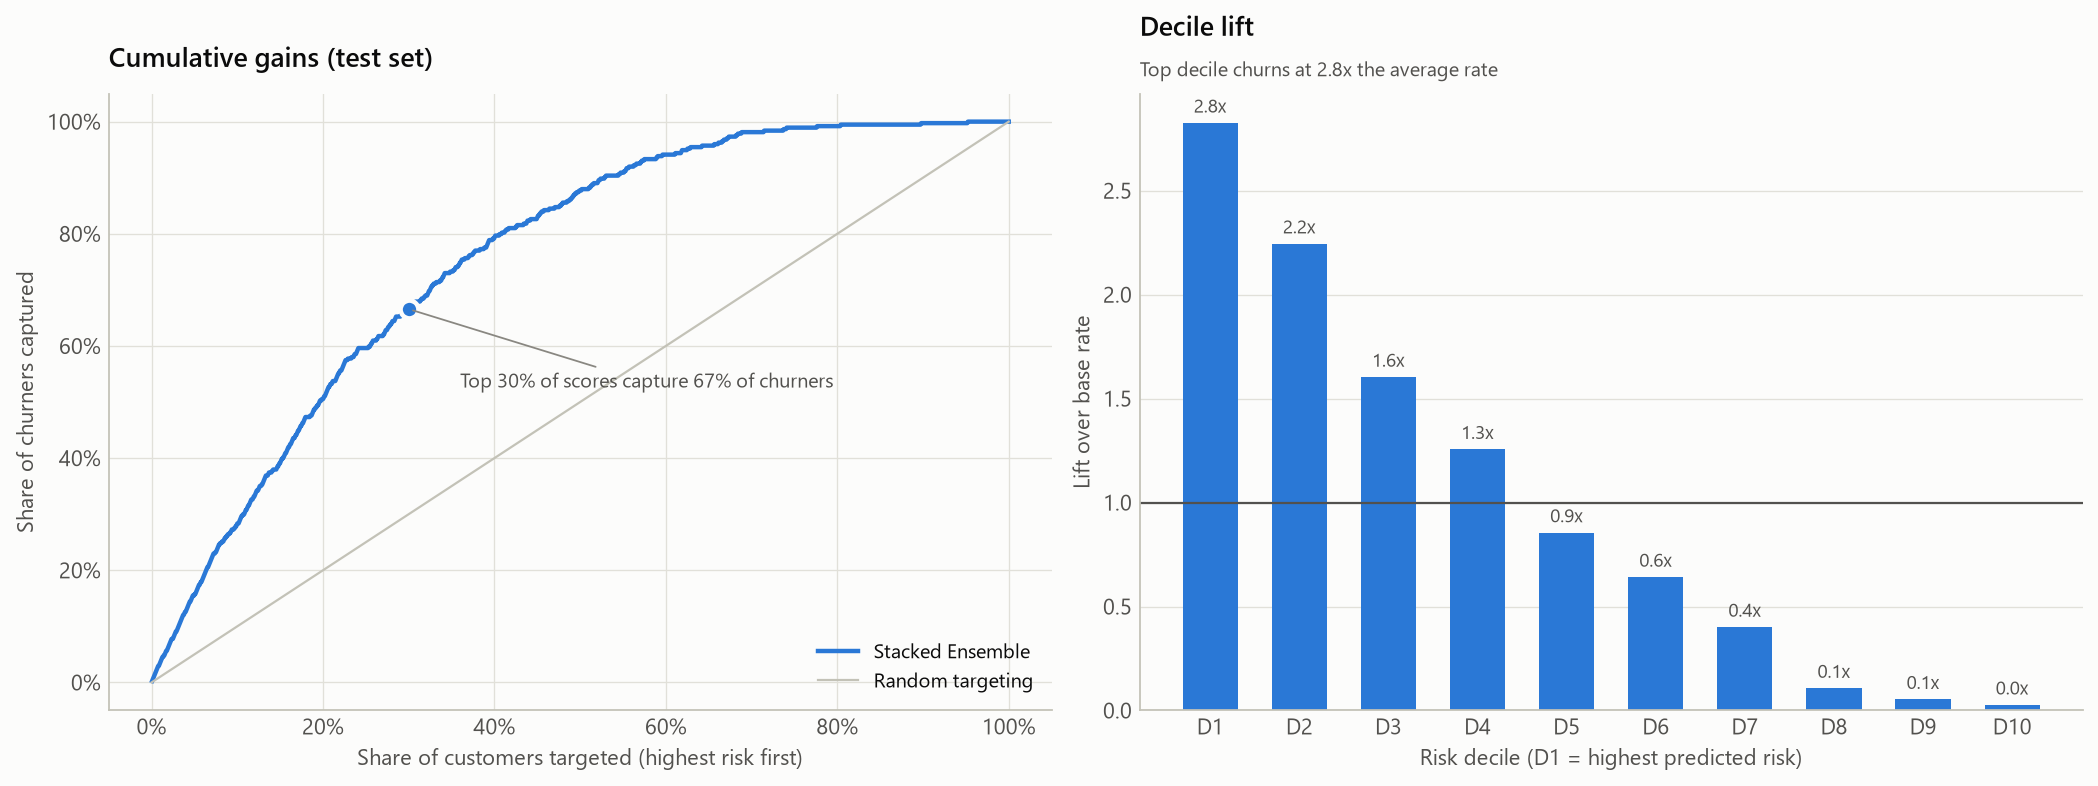

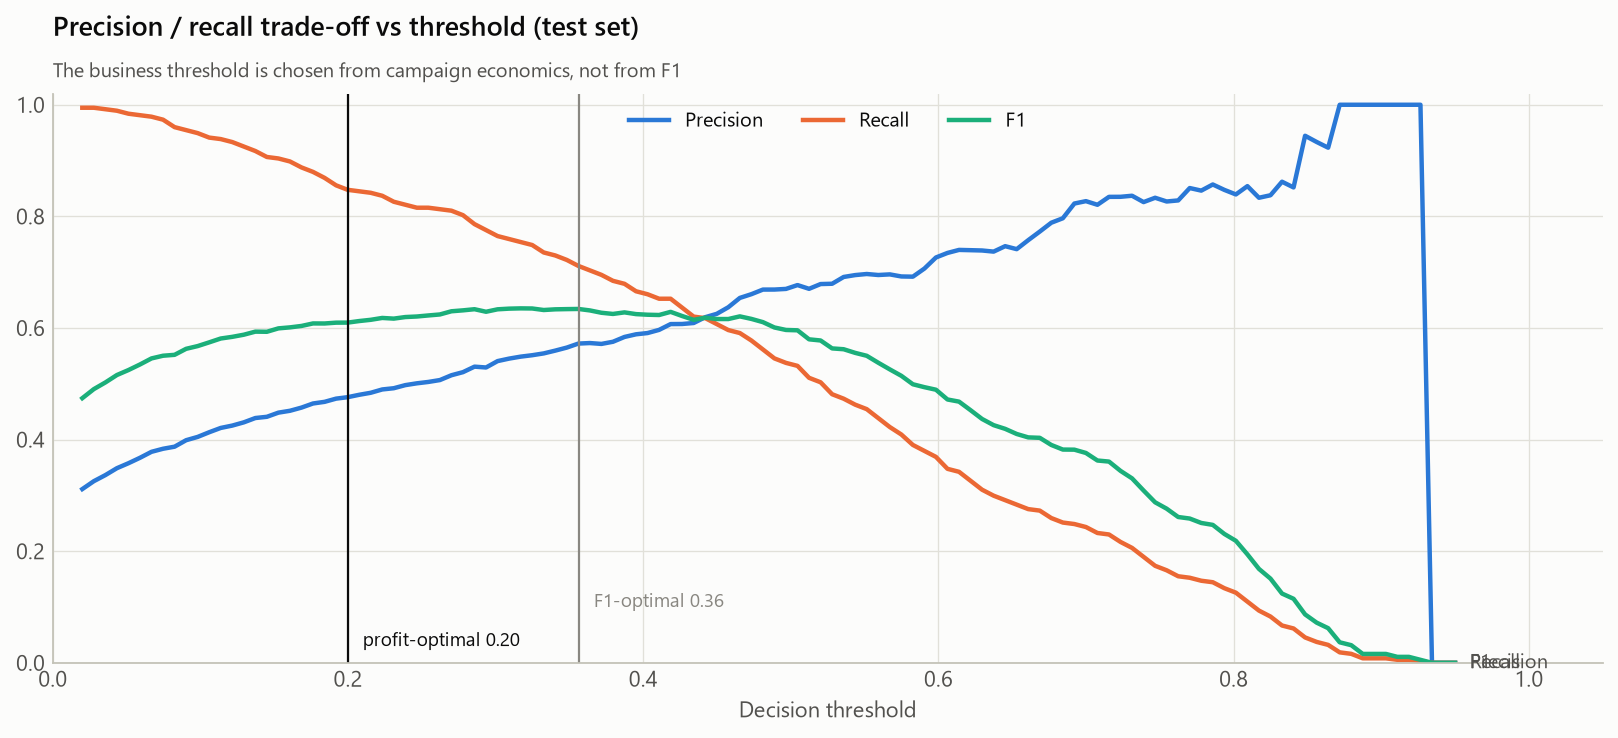

In [19]:
show("confusion_matrix", 520); show("gains_lift", 1150); show("threshold_tradeoff", 950)

## 6. Business economics

Margin at risk = MonthlyCharges x horizon x gross margin. Targeting costs contact + incentive; a share of targeted
churners is saved. With calibrated probabilities the profit-maximising rule needs no tuning:
**contact customer *i* iff p_i x success x value_i > cost**.

In [20]:
print(md_["business_params"])
pol = pd.DataFrame(M["business"]["policies_test"]).set_index("policy")
scale = M["business"]["scale_to_full_base"]
(pol[["n_targeted", "churners_reached", "campaign_cost", "retained_value", "net_profit"]] * scale).round(0).join(pol["roi"].round(2))

{'clv_horizon_months': 24, 'gross_margin': 0.6, 'contact_cost': 10.0, 'incentive_cost': 60.0, 'offer_success_rate': 0.35}


,n_targeted,churners_reached,campaign_cost,retained_value,net_profit,roi
policy,,,,,,
No campaign,0.0,0.0,0.0,0.0,0.0,0.00
Target everyone,7043.0,1869.0,493010.0,685621.0,192611.0,0.39
Uniform threshold (p >= 0.20),3329.0,1585.0,233034.0,593790.0,360757.0,1.55
Value-aware rule (p*s*v > c),3134.0,1490.0,219388.0,593469.0,374081.0,1.71
Oracle (perfect foresight),1869.0,1869.0,130863.0,685621.0,554758.0,4.24


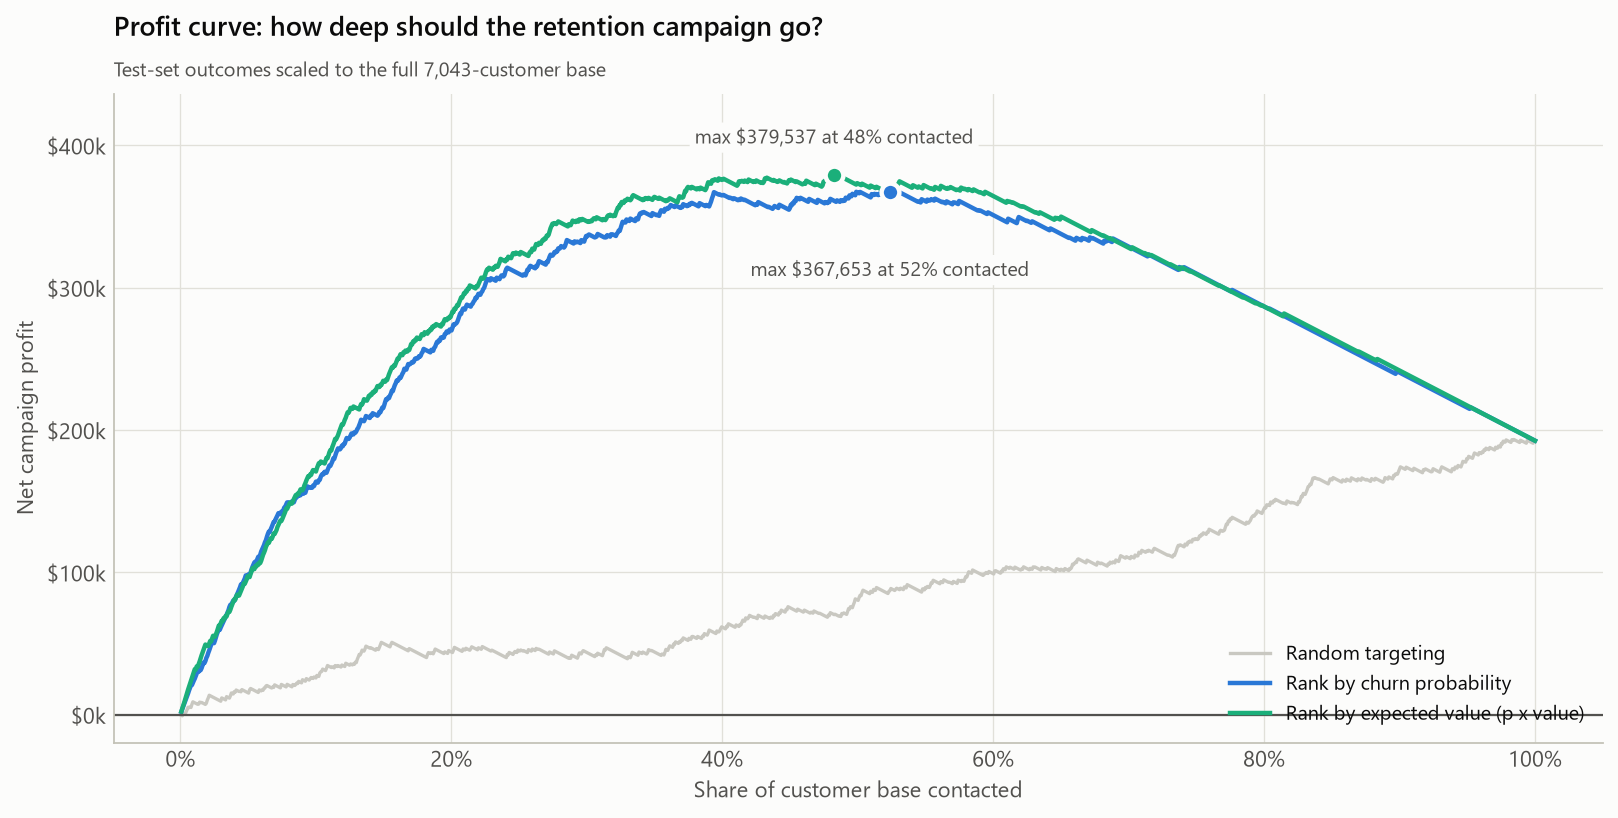

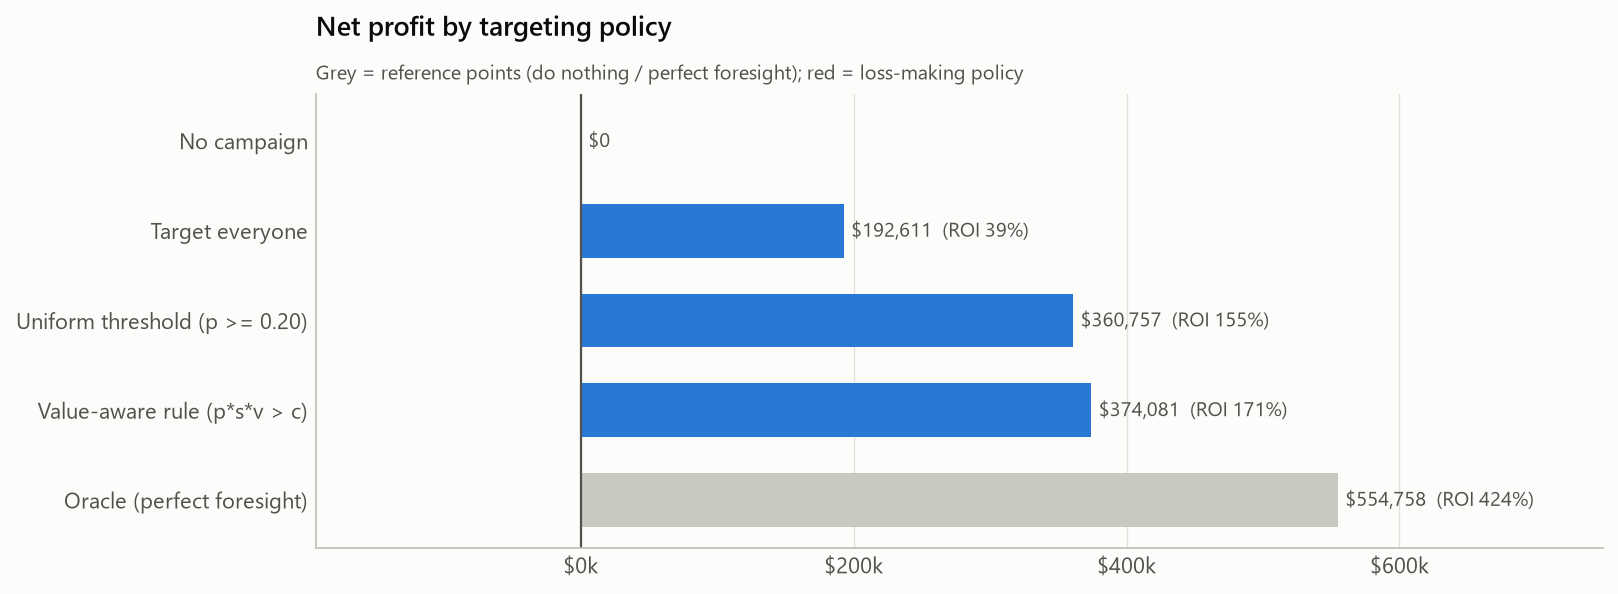

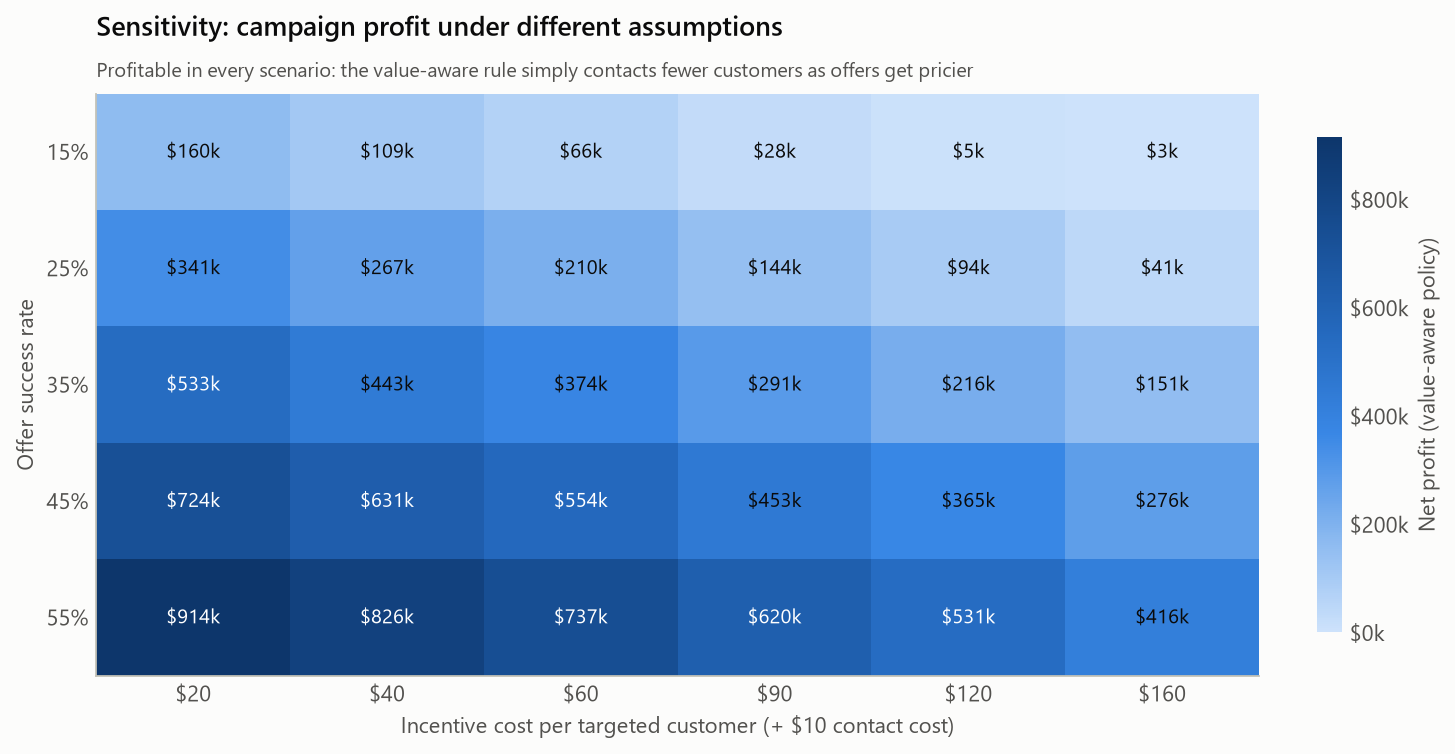

In [21]:
show("business_profit_curve", 1000); show("business_policy_comparison", 1000); show("business_sensitivity", 900)

## 7. Explainability

SHAP values are computed on the **deployed** model in the space of the original attributes (categoricals exposed to
the explainer as codes and decoded before prediction), so contributions read as percentage points of churn
probability. Permutation importance on the hold-out set and TreeSHAP on the best GBM are cross-checks.

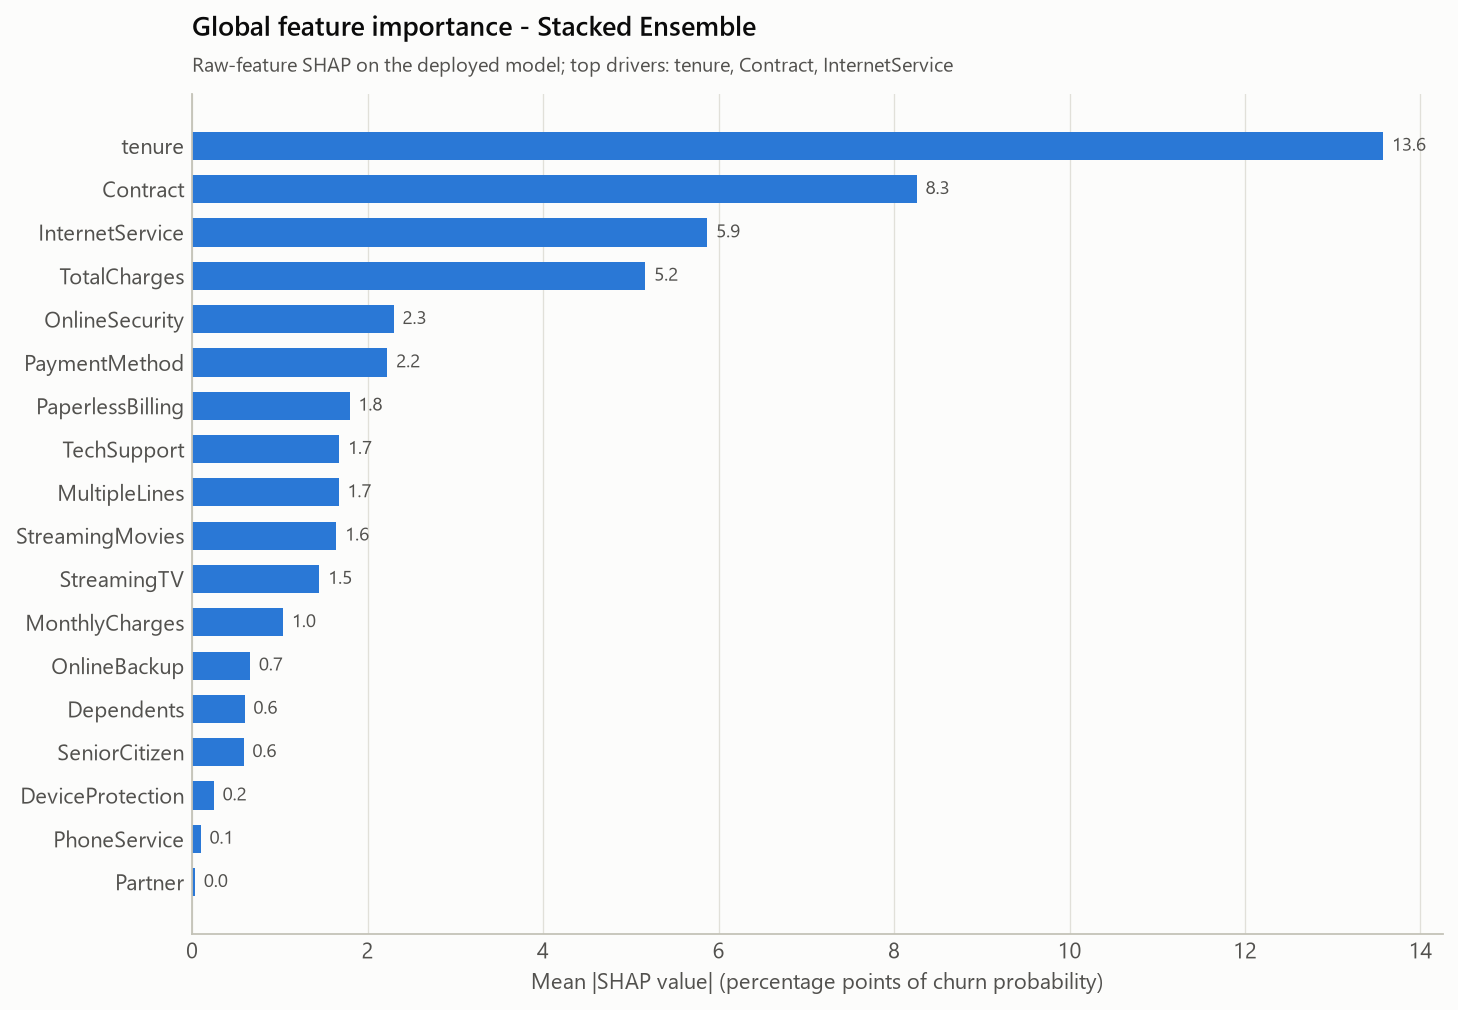

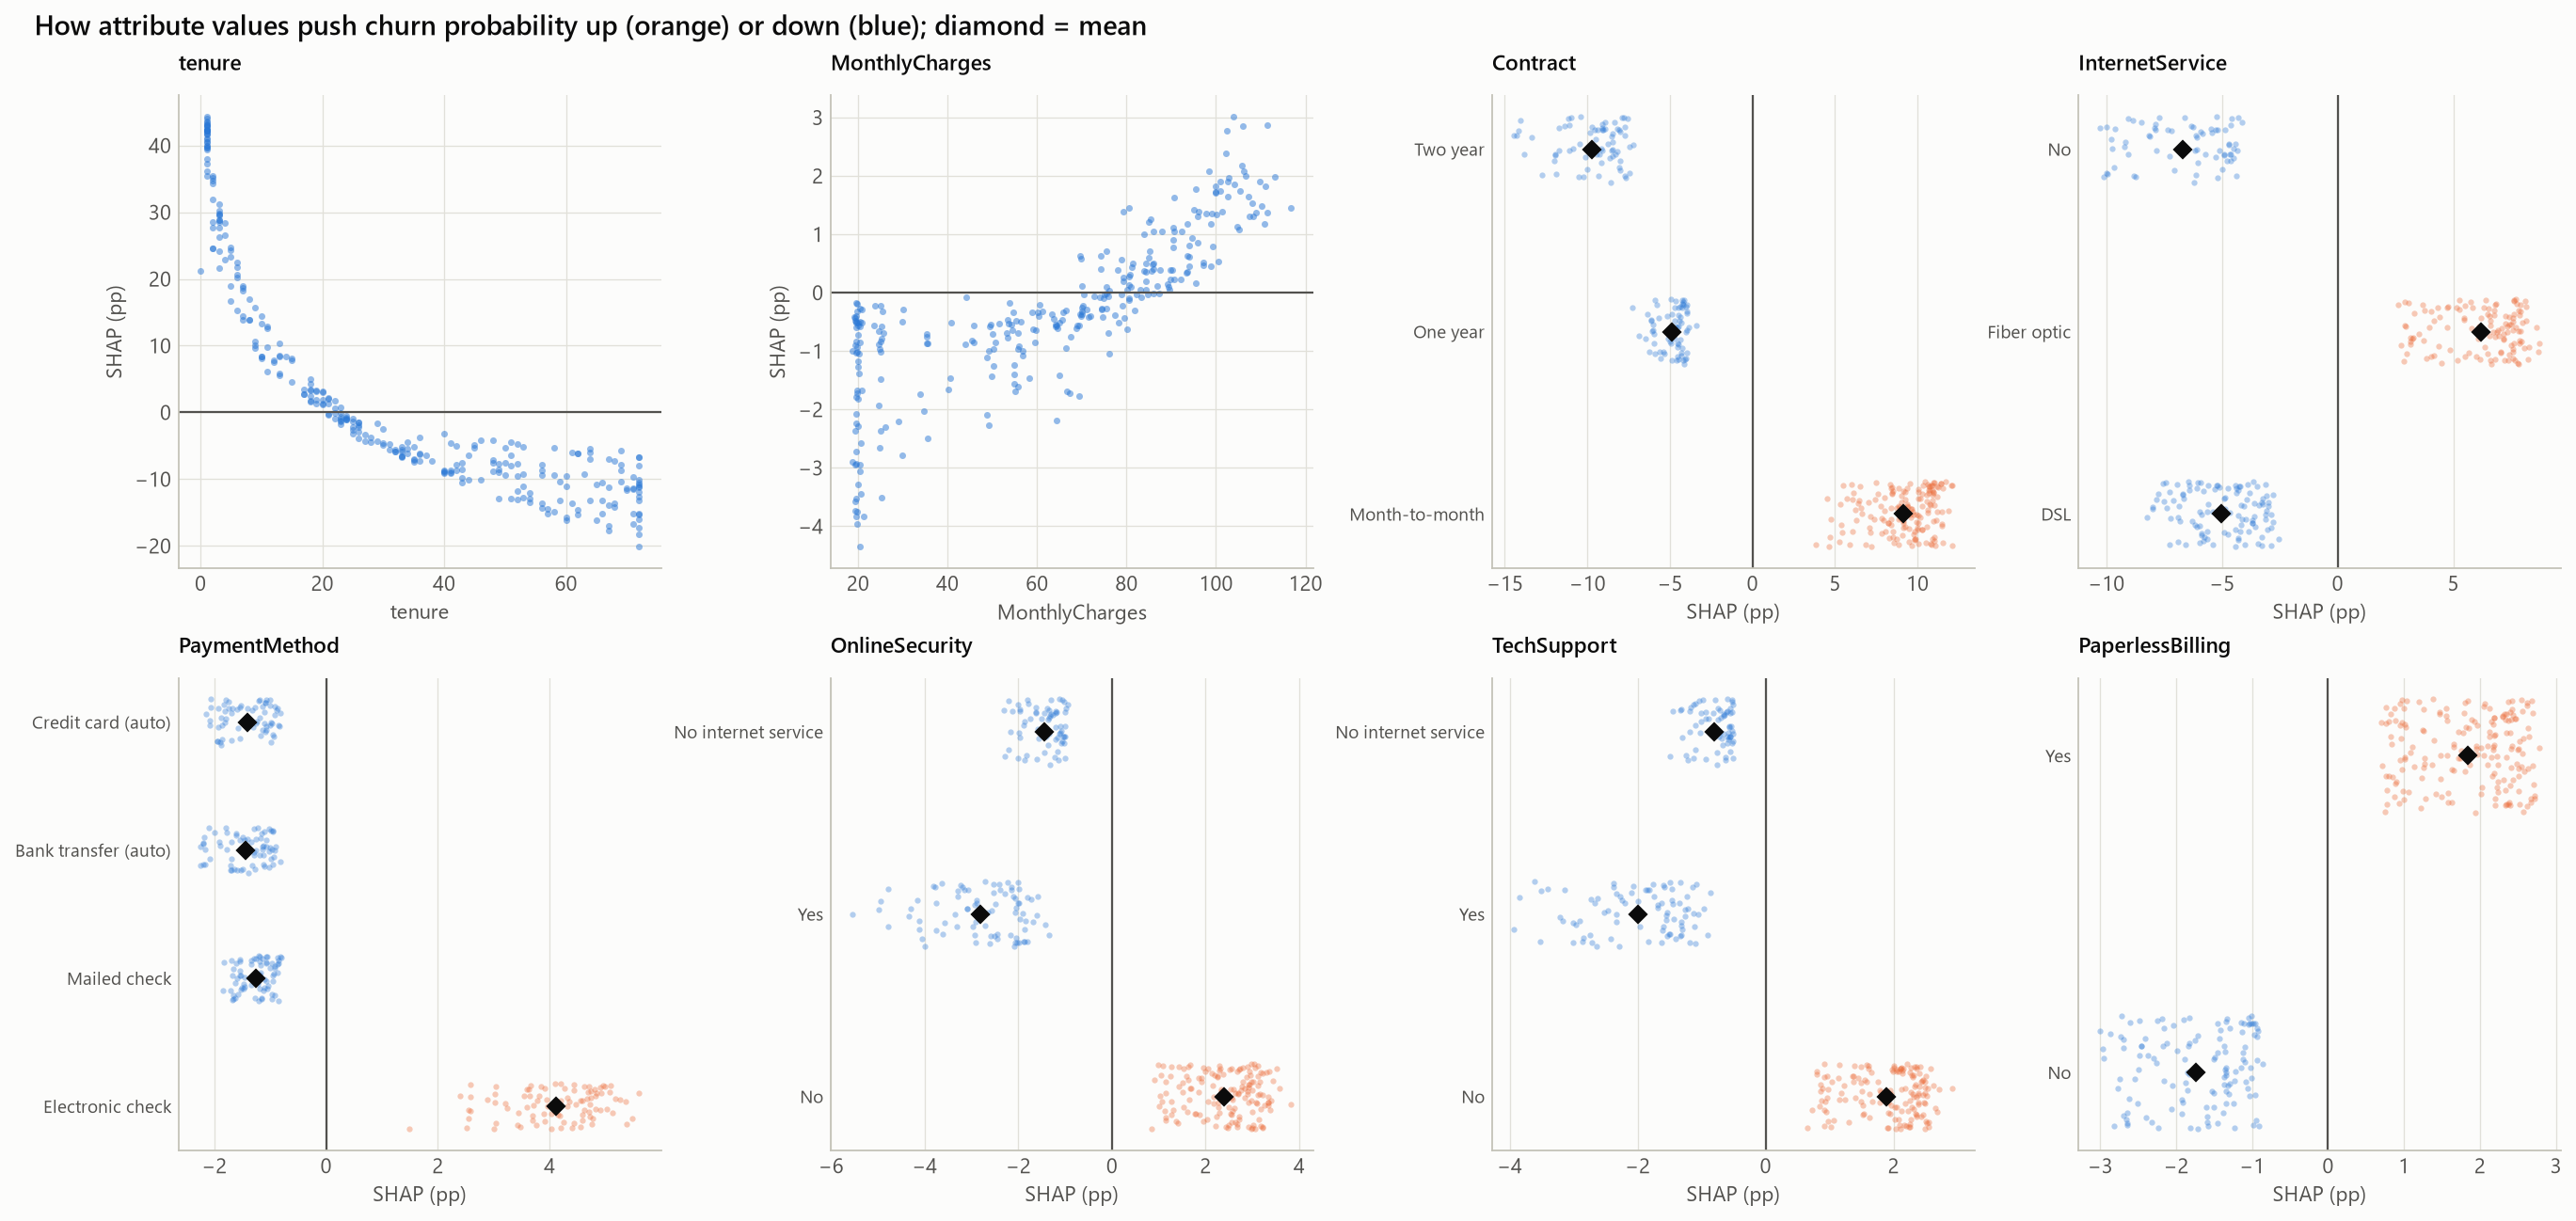

In [22]:
show("shap_global_importance", 850); show("shap_dependence", 1250)

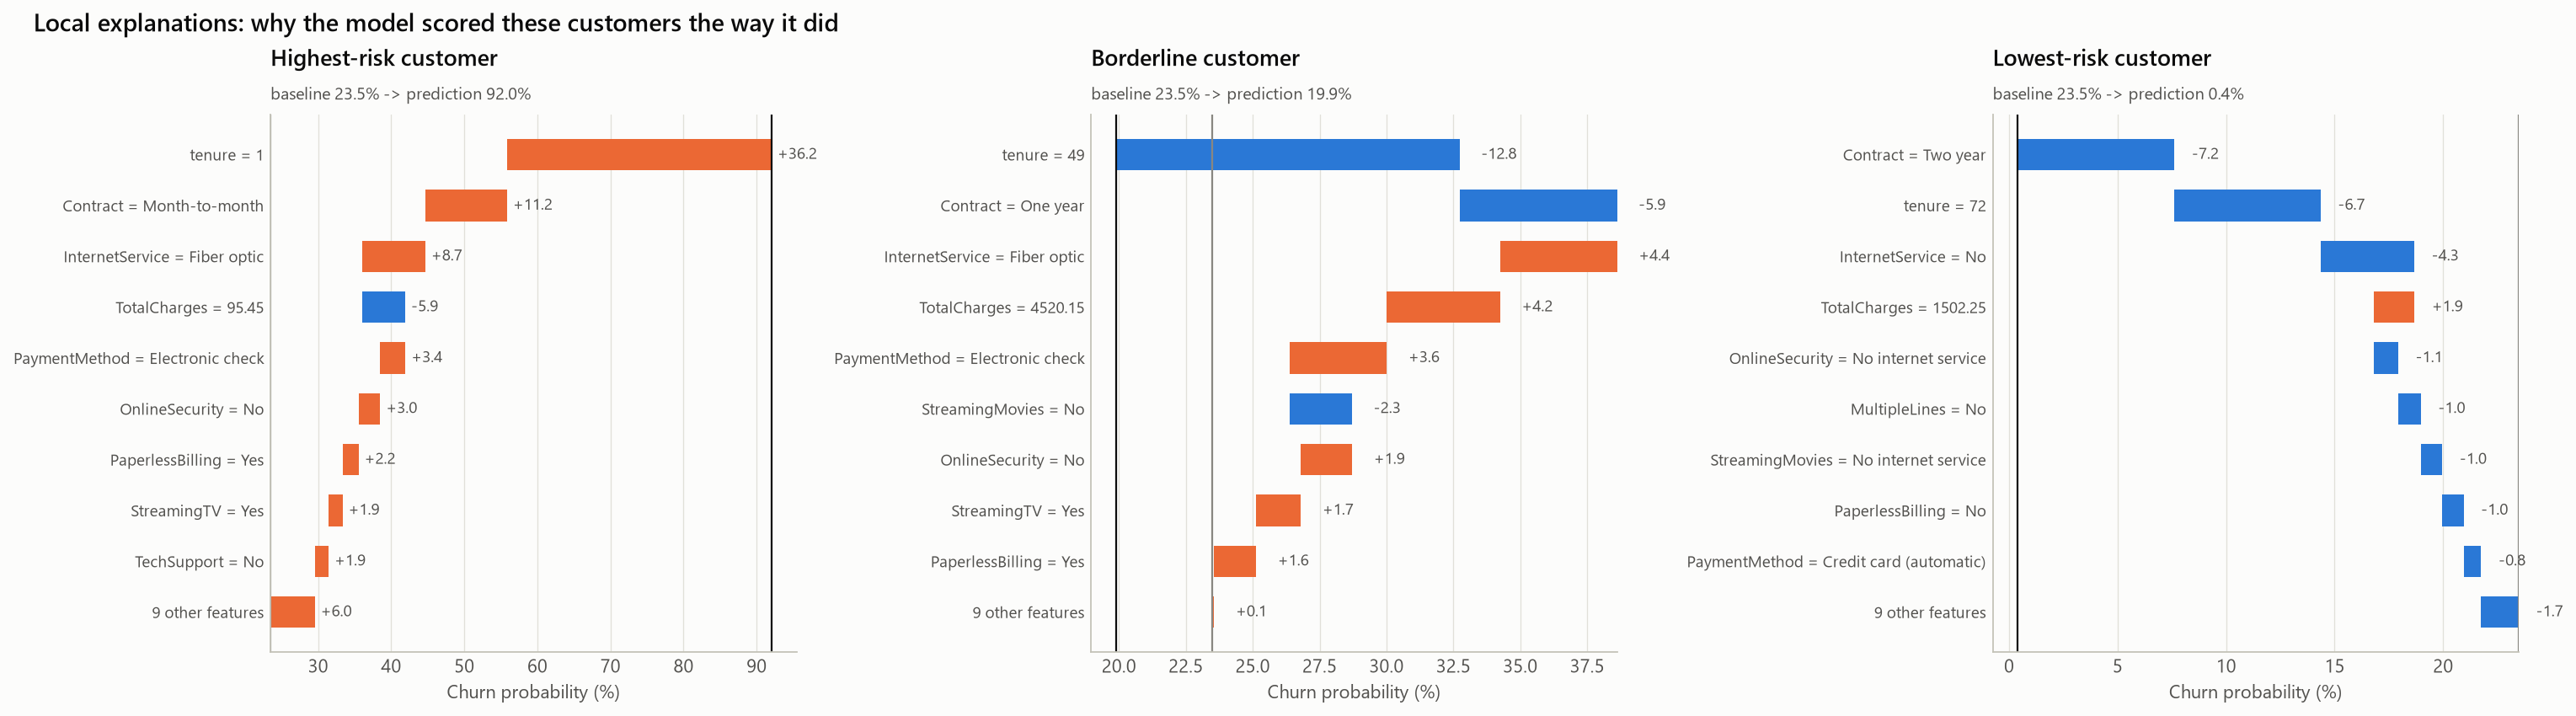

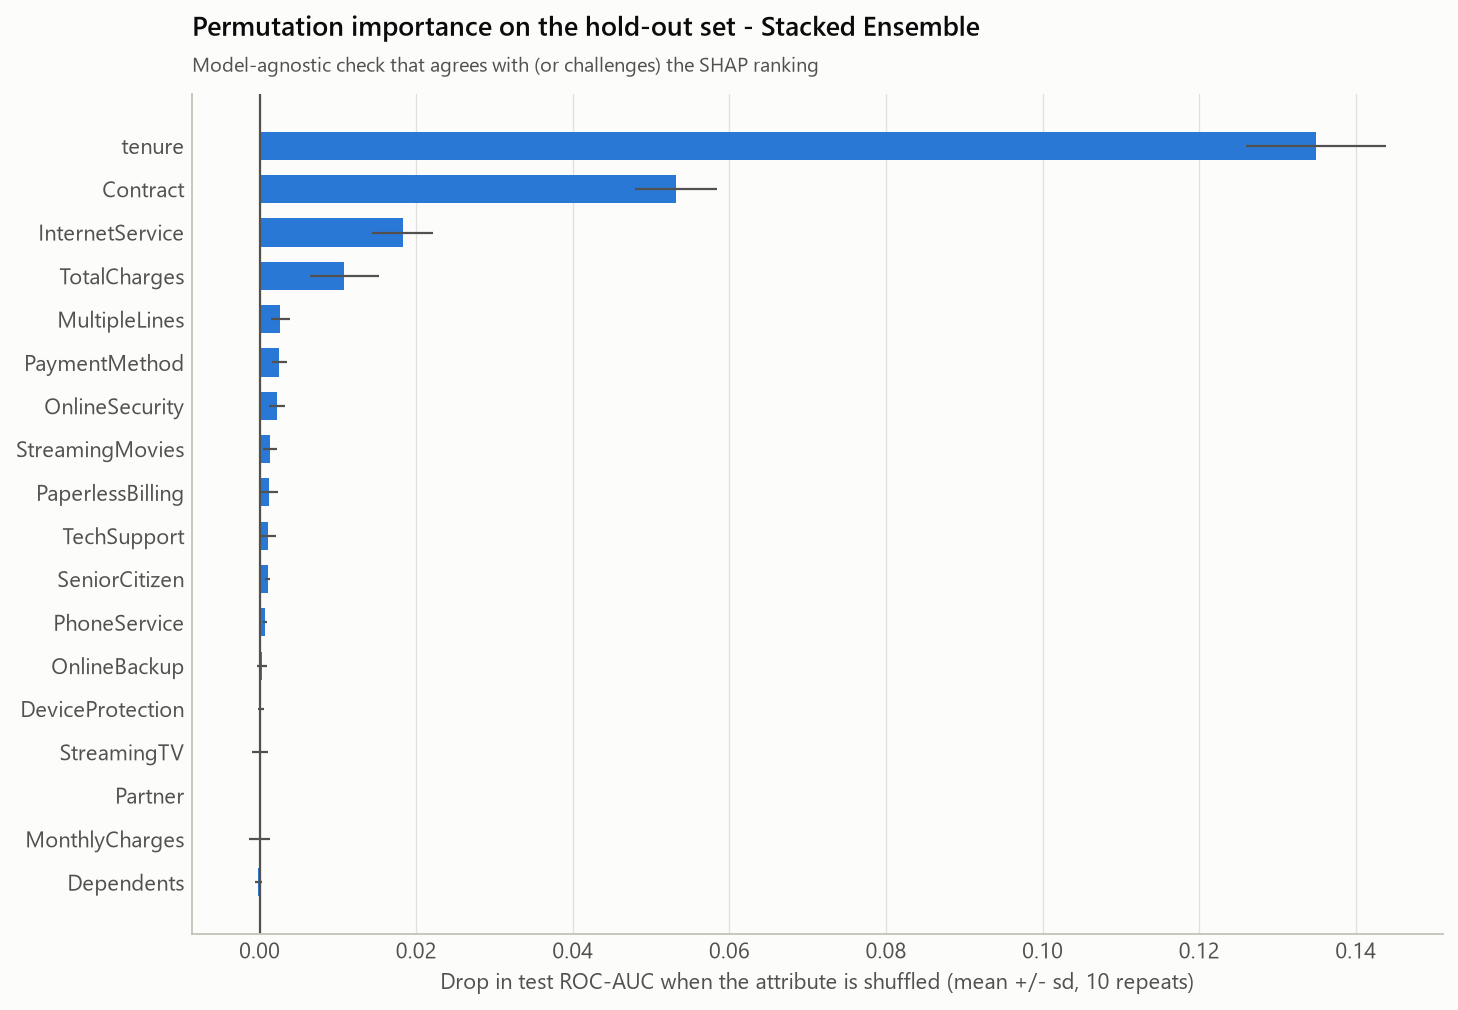

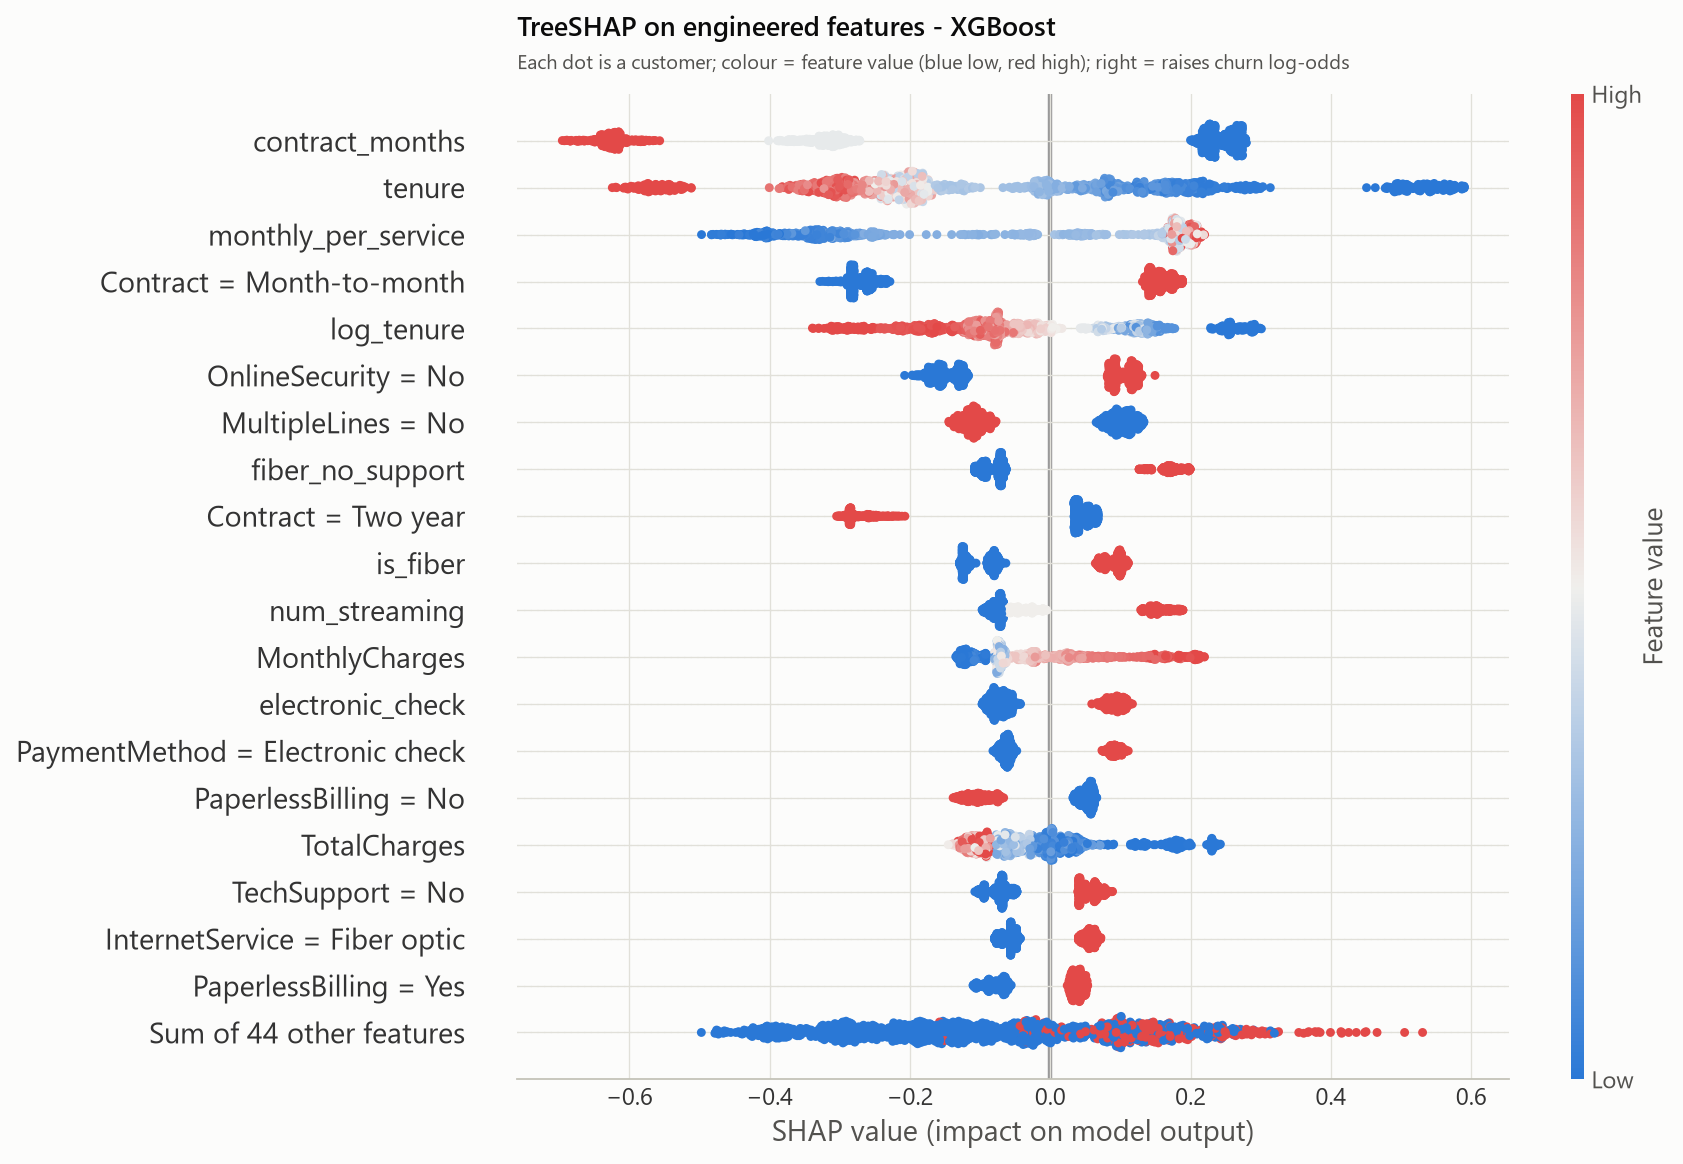

In [23]:
show("shap_local_examples", 1250); show("permutation_importance", 850); show("shap_tree_beeswarm", 850)

## 8. Segmentation and fairness

,segment,customers,actual_churn_rate,mean_predicted_risk,avg_monthly_charges,avg_tenure,expected_margin_loss,share_of_expected_loss,playbook
0,Priority save,2196,0.5159,0.5201,89.3011,24.2914,1.4545e+06,0.7221,Proactive outreach by a retention specialist; ...
1,Low-cost save,1161,0.4195,0.4167,45.9343,7.6150,3.3471e+05,0.1662,"Automated digital offer (auto-pay credit, free..."
2,Protect & grow,1328,0.0791,0.0796,92.6631,58.4842,1.4465e+05,0.0718,Loyalty perks and upsell of protection bundles...
3,Maintain,2358,0.0611,0.0596,35.4644,37.3783,8.0385e+04,0.0399,Business as usual; monitor for risk changes


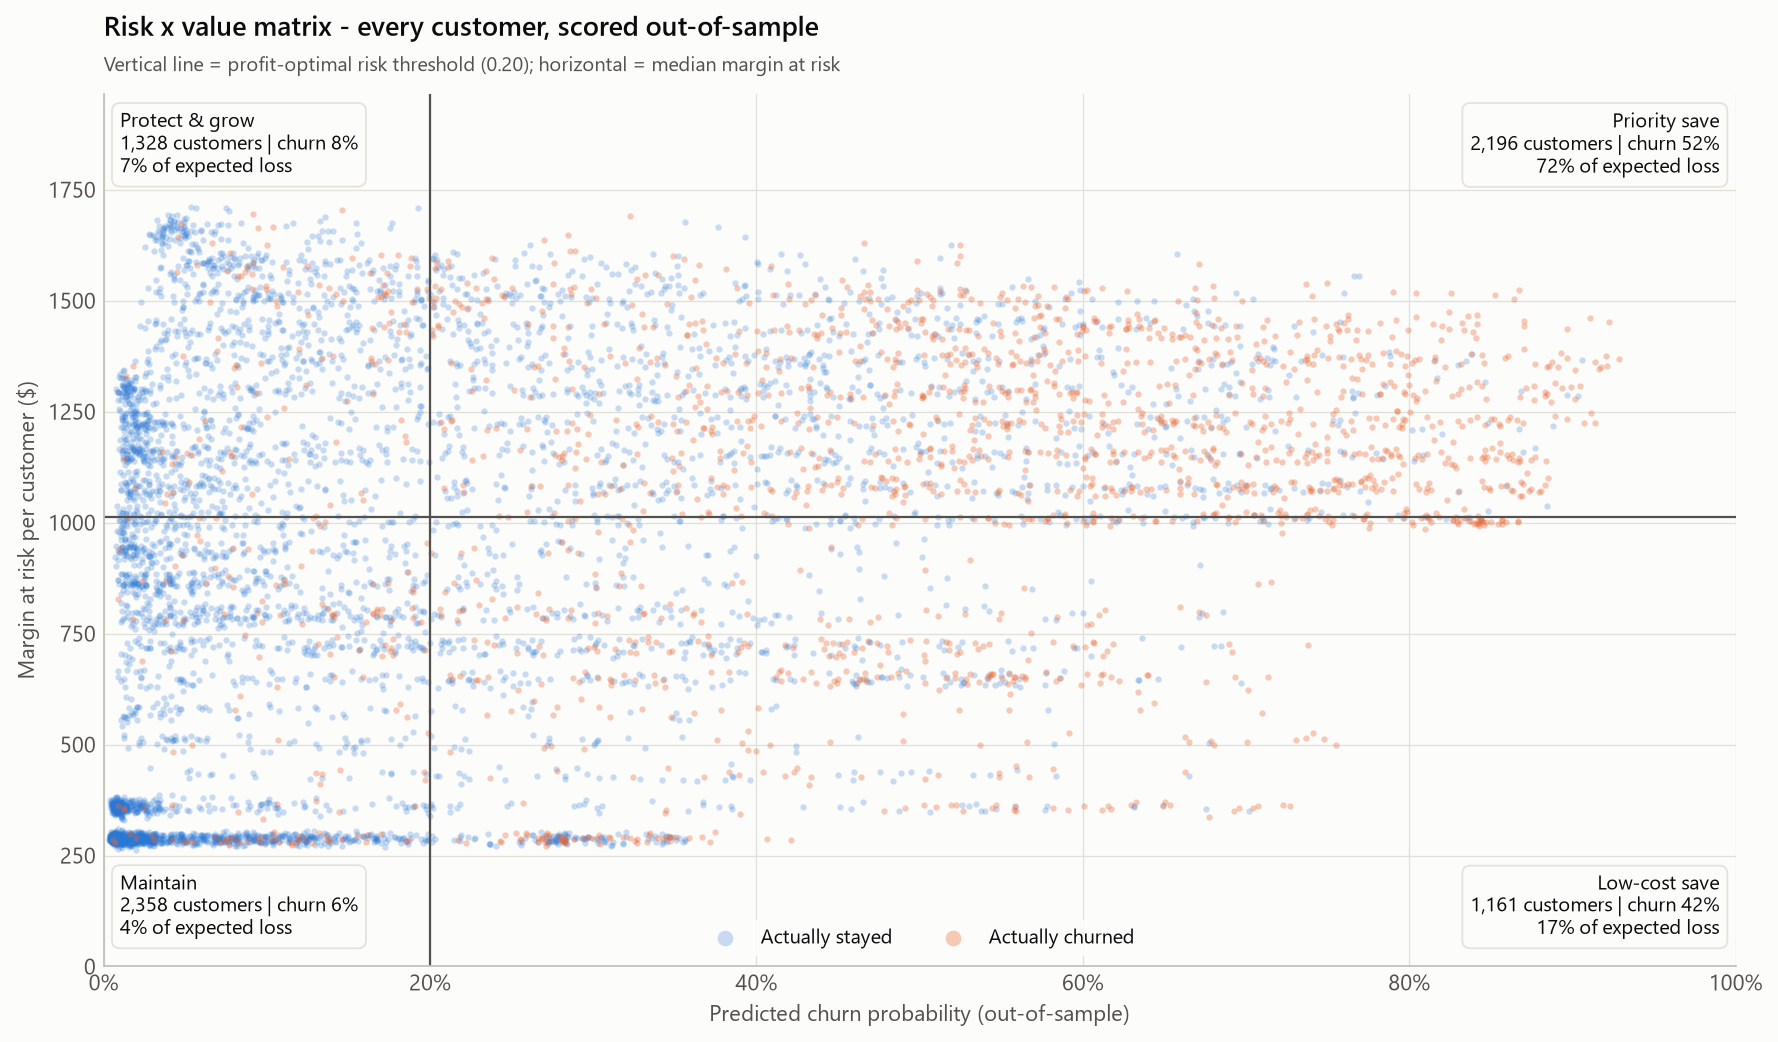

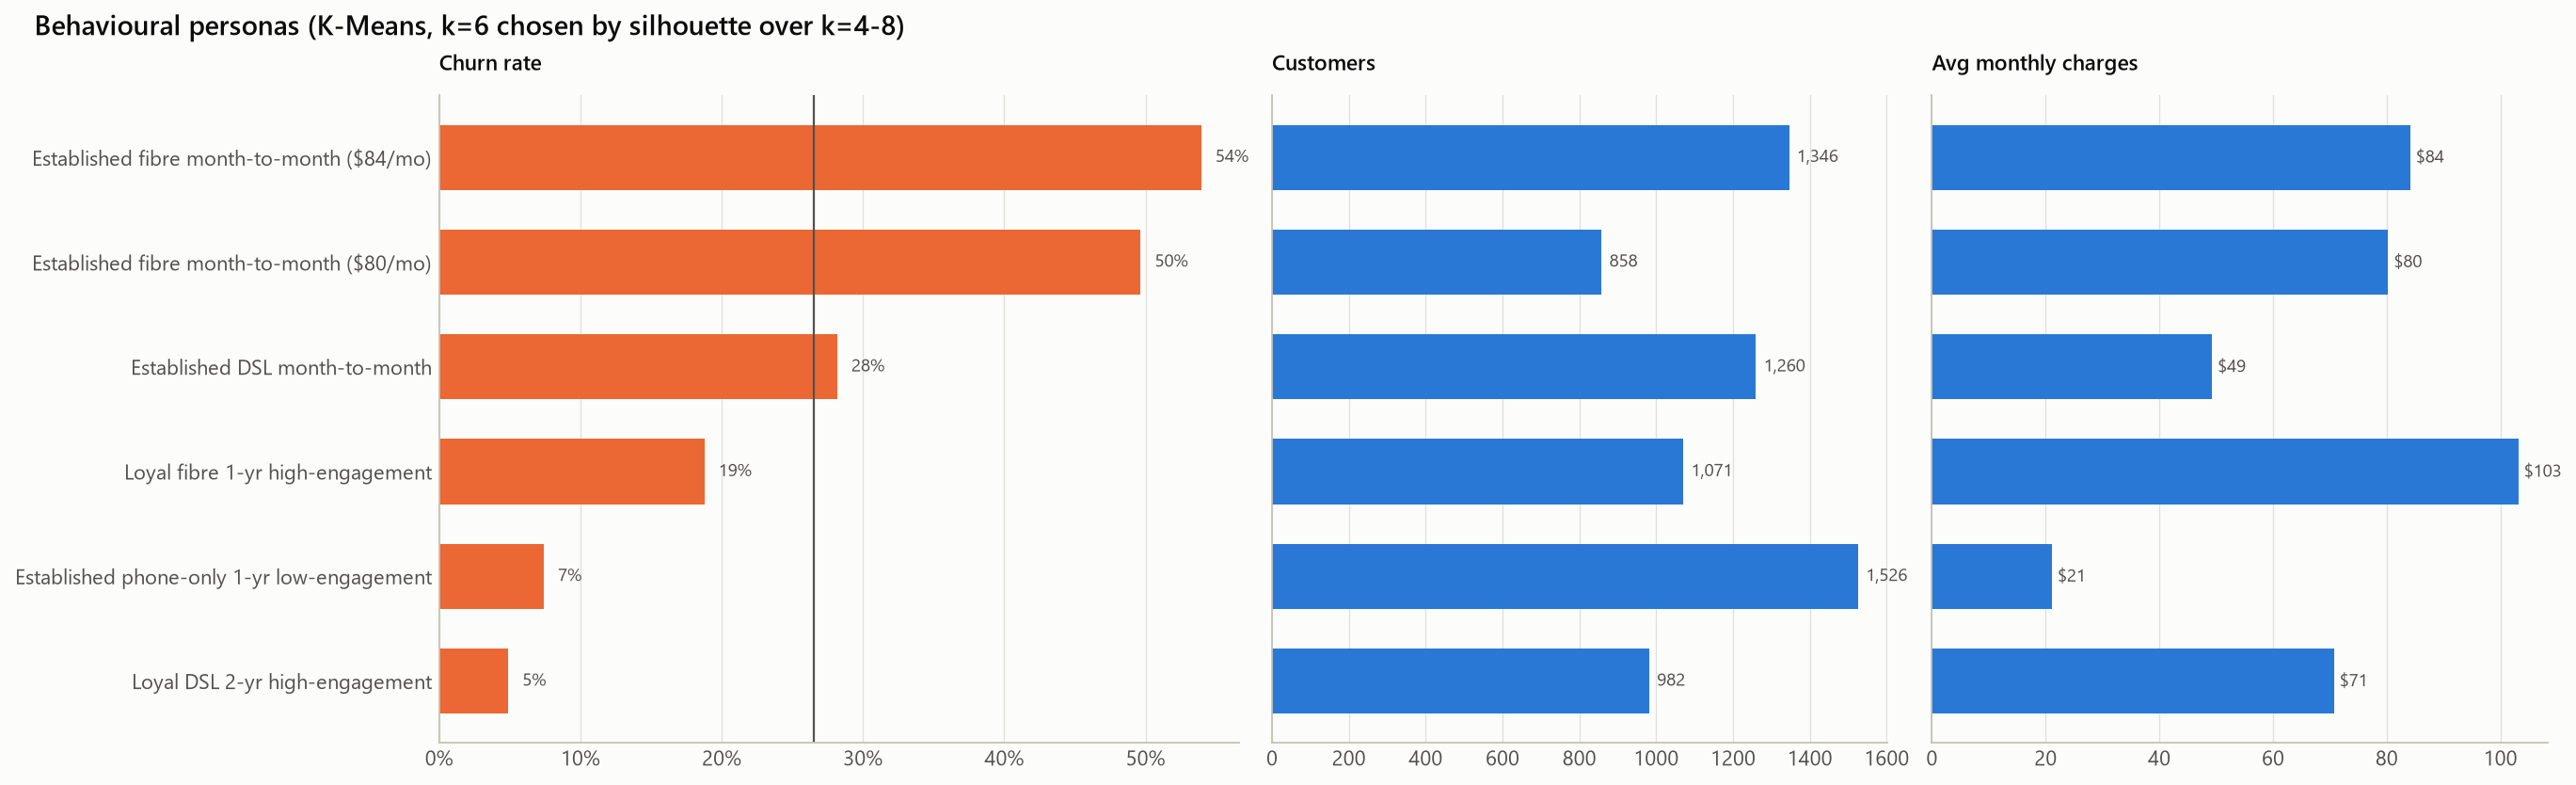

In [24]:
display(pd.read_csv(TAB / "segment_summary.csv"))
show("segmentation_risk_value_matrix", 1000); show("segmentation_personas", 1200)

,attribute,tpr_gap,fpr_gap,auc_gap,selection_rate_ratio,base_rate_ratio
0,Dependents,0.1490,0.2148,0.0204,0.4935,0.5317
1,Partner,0.0526,0.1430,0.0301,0.6467,0.5556
2,SeniorCitizen,0.1924,0.3260,0.0678,0.5152,0.5267
3,gender,0.0084,0.0117,0.0053,0.9918,0.8924


gender ablation: {'without_gender': {'cv_auc_mean': 0.8499635653730213, 'cv_auc_std': 0.011674418826206345}, 'with_gender': {'cv_auc_mean': 0.8501764796291669, 'cv_auc_std': 0.011758899957700346}}


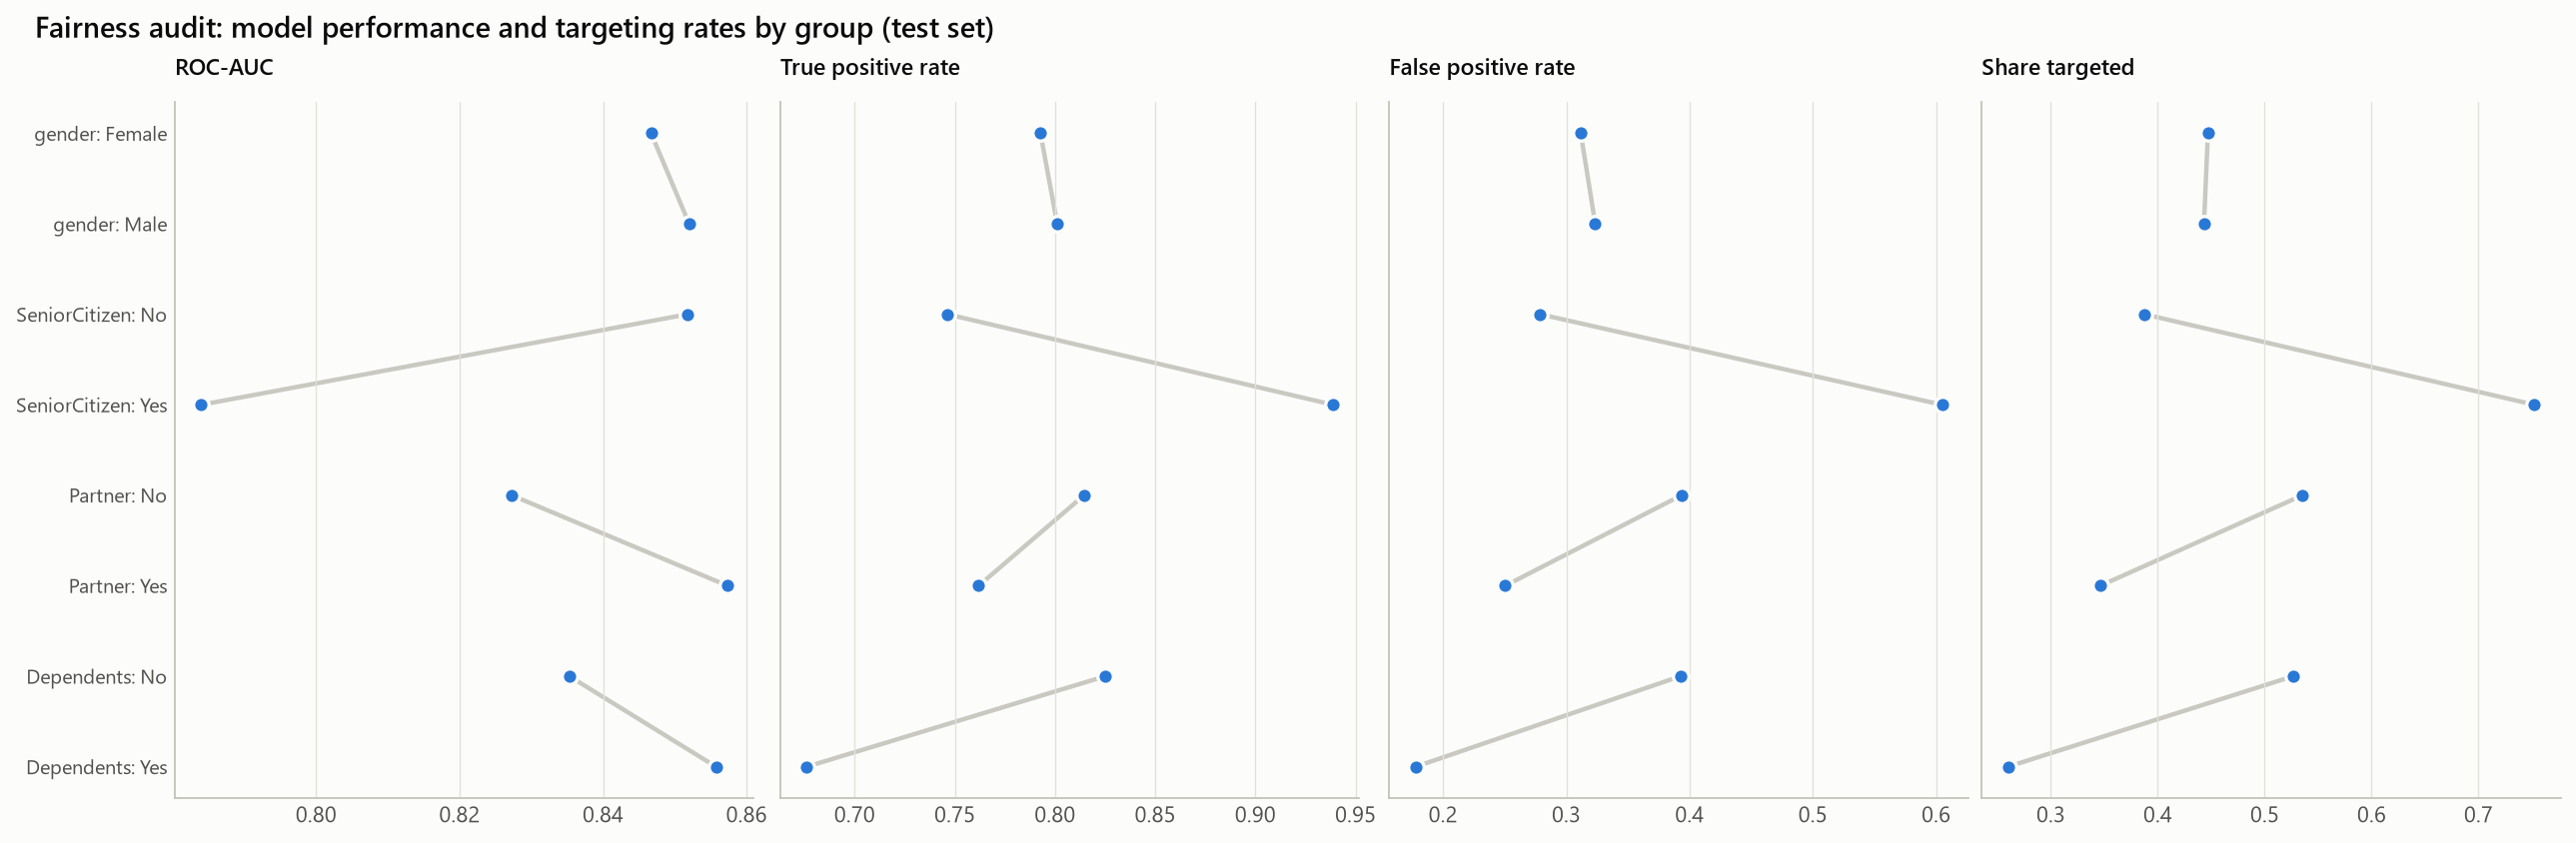

In [25]:
display(pd.read_csv(TAB / "fairness_disparity.csv"))
print("gender ablation:", M["fairness"]["gender_ablation"])
show("fairness_group_parity", 1200)

## 9. Live scoring

The deployed artefact is the full inference path (feature engineering included), wrapped by `ChurnPredictor`.

In [26]:
pred = ChurnPredictor.load(ROOT / "models")
_, X_test, _, y_test = data.split(df)
pred.score(X_test.head(8)).assign(actual_churn=y_test.head(8).values)

C:\Users\thode.s.prajwal\.venvs\telco-churn\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,customerID,churn_probability,risk_tier,value_at_risk,expected_campaign_value,target_for_retention,above_uniform_threshold,actual_churn
437,4376-KFVRS,0.0383,Low,1642.32,-47.97,False,False,0
2280,2754-SDJRD,0.6965,Critical,1442.16,281.55,True,True,0
2235,9917-KWRBE,0.0686,Low,1128.24,-42.91,False,False,0
4460,0365-GXEZS,0.3296,Medium,1126.08,59.89,True,True,0
3761,9385-NXKDA,0.0217,Low,1190.16,-60.95,False,False,0
5748,4686-UXDML,0.5760,High,1437.84,219.84,True,True,0
3568,2227-JRSJX,0.4273,High,1427.76,143.53,True,True,0
2976,4830-FAXFM,0.1097,Low,347.04,-56.68,False,False,0


In [27]:
risky = X_test.iloc[[int(pred.predict_proba(X_test).argmax())]]  # the highest-risk hold-out customer
display(risky.T)
display(pred.explain(risky).head(8))
pred.next_best_actions(risky)

,3380
customerID,5178-LMXOP
gender,Male
SeniorCitizen,1
Partner,Yes
Dependents,No
tenure,1
PhoneService,Yes
MultipleLines,Yes
InternetService,Fiber optic
OnlineSecurity,No


,feature,value,contribution,base_value
0,tenure,1,0.3839,0.2349
1,Contract,Month-to-month,0.0999,0.2349
2,InternetService,Fiber optic,0.0666,0.2349
3,PaymentMethod,Electronic check,0.0354,0.2349
4,TotalCharges,95.1,-0.0275,0.2349
5,OnlineSecurity,No,0.0233,0.2349
6,StreamingTV,Yes,0.0174,0.2349
7,TechSupport,No,0.0170,0.2349


,action,new_probability,risk_reduction,new_value_at_risk
0,Upgrade to a 2-year contract (price lock),0.6296,0.2988,1369.440
1,Upgrade to a 1-year contract (with loyalty dis...,0.7862,0.1422,1369.440
2,Bundle Online Security free for 6 months,0.8666,0.0618,1369.440
3,Bundle Tech Support free for 6 months,0.8800,0.0484,1369.440
4,Move to automatic card payment (bill credit),0.8934,0.0350,1369.440
5,15% loyalty discount on monthly bill,0.9203,0.0081,1163.952


The next-best-action table is a **model-implied** simulation - it ranks which offers are worth testing. Proving
causal lift needs a randomised campaign and, ultimately, an uplift model trained on its results.

## Conclusions

* Churn is concentrated in **new, month-to-month, fibre customers without protection add-ons who pay by electronic
  check** - consistent across descriptive stats, adjusted odds ratios, Cox hazard ratios and SHAP.
* Six tuned model families and two ensembles land within a narrow AUC band; the deployed model was chosen by CV, and its edge over
  logistic regression is tested, not assumed.
* The value of the model is in the **decision**: value-aware targeting on calibrated probabilities beats blanket
  campaigns and uniform thresholds, and stays profitable across a wide range of offer costs and success rates.